# Capstone Milestone Two — Week 11: Clustering Part 2 (DBSCAN and Hierarchical Agglomerative Clustering)

**Kumar Gaurav · DX799 O1 Data Science Capstone**

## Project Overview

Week 10 introduced unsupervised learning with **k-means**: a centroid-based method that needs *k* up front, assumes roughly convex, similarly sized clusters, and assigns every observation to some cluster. This week tests those assumptions with two structurally different families:

* **DBSCAN** (Density-Based Spatial Clustering of Applications with Noise) — clusters are regions of high point density separated by low-density gaps. The number of clusters is discovered, arbitrary shapes are allowed, and observations in sparse regions are labelled **noise** rather than forced into a cluster.
* **Hierarchical Agglomerative Clustering (HAC)** — a bottom-up procedure that starts with every observation as its own cluster and repeatedly merges the two closest clusters. The **linkage method** defines "closest", and the full merge history is visualized as a **dendrogram**, which is then cut to obtain a partition.

The default label (`default`) is again held out of every fit and used only *ex post* to check whether the unsupervised structure carries credit-risk information.

### Research Question

Do the Lending Club and Taiwan credit datasets contain **density-separated** or **hierarchically nested** borrower segments that k-means could not express, how sensitive are those segments to DBSCAN's `eps` / `min_samples` and to the HAC linkage method, and which approach yields the most useful segmentation for the capstone?

### Learning Objectives (Week 11)

* Explain how DBSCAN identifies **core**, **border**, and **noise** points from `eps` and `min_samples` (MinPts), and define a DBSCAN cluster through **core-point connectivity**.
* Compare **single, complete, average, and Ward** linkage and explain how each one influences which clusters merge.
* Interpret **dendrograms** to choose a suitable number of clusters for HAC.
* Answer the *Think About It* questions: the effect of poorly chosen `eps` / MinPts, why linkages disagree on the same data, and when to prefer DBSCAN over HAC.

### Approach

Data Loading → Shared Clustering Setup → Scaling and Distance Diagnostics → DBSCAN (k-distance, sensitivity grid, final fit, core/border/noise, profiling, feature ablation) → HAC with four linkages → Linkage Comparison → Dendrograms and Cut Selection → Final HAC Profiling → DBSCAN vs HAC vs k-means Agreement → Scalability → Consolidated Comparison → Conclusions

### Datasets

Same as Weeks 4–10 for continuity:

* **Lending Club** (Kaggle `adarshsng/lending-club-loan-data-csv`): US peer-to-peer installment loans, 2007–2018.
* **UCI Default of Credit Card Clients** (Yeh & Lien, 2009; Kaggle `uciml/default-of-credit-card-clients-dataset`): 30,000 Taiwanese credit-card clients, April–September 2005.

## 1. Data Loading and Cleaning

The next two cells repeat the Week 6/9/10 cleaning verbatim so this notebook is self-contained and its results line up with Week 10: drop open loans with unknown outcome, drop invalid ranges, recode undocumented codes, remove post-outcome columns to prevent target leakage, and log-transform heavily skewed money columns. Identifiers (`id`, `ID`) are dropped and never used as features.

In [1]:
import os, warnings, time
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import kagglehub
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.width", 160)
SEED = 42
np.random.seed(SEED)

# Lending Club: read only the columns the Week 6 audit uses
LC_PATH = os.path.join(kagglehub.dataset_download("adarshsng/lending-club-loan-data-csv/versions/1"), "loan.csv")
LC_COLS = ["id", "loan_status", "loan_amnt", "term", "int_rate", "grade", "sub_grade", "emp_length",
           "home_ownership", "annual_inc", "verification_status", "purpose", "dti", "delinq_2yrs",
           "inq_last_6mths", "open_acc", "pub_rec", "revol_bal", "revol_util", "total_acc", "mort_acc",
           "pub_rec_bankruptcies", "application_type", "policy_code",
           "total_pymnt", "recoveries", "last_pymnt_amnt", "out_prncp"]  # leakage columns, dropped below
lc_raw = pd.read_csv(LC_PATH, usecols=LC_COLS, low_memory=False)

CLOSED = ["Fully Paid", "Charged Off", "Default"]
lc = lc_raw[lc_raw["loan_status"].isin(CLOSED)].drop(columns=["id"]).drop_duplicates().copy()
n_closed = len(lc)
lc.loc[(lc["dti"] < 0) | (lc["dti"] > 100), "dti"] = np.nan
lc["revol_util"] = lc["revol_util"].clip(upper=150)
lc = lc[lc["annual_inc"] > 0]
lc["home_ownership"] = lc["home_ownership"].replace({"ANY": "OTHER", "NONE": "OTHER"})
const = [c for c in lc.columns if lc[c].nunique(dropna=False) <= 1]
lc = lc.drop(columns=const)
lc = lc.drop(columns=["total_pymnt", "recoveries", "last_pymnt_amnt", "out_prncp"])  # leakage
lc["default"] = (lc["loan_status"] != "Fully Paid").astype(int)
n_before_na = len(lc)
lc = lc.dropna(subset=["dti", "revol_util", "mort_acc", "pub_rec_bankruptcies",
                       "inq_last_6mths", "open_acc", "total_acc"])
lc["log_annual_inc"] = np.log1p(lc["annual_inc"])
lc["log_revol_bal"]  = np.log1p(lc["revol_bal"])
lc["term_months"]    = lc["term"].str.extract(r"(\d+)").astype(int)
print(f"Closed, de-duplicated loans: {n_closed:,} | after range filters: {n_before_na:,} "
      f"| after dropping incomplete rows: {len(lc):,} ({1 - len(lc)/n_before_na:.2%} removed, documented)")
print(f"Clean Lending Club rows: {len(lc):,} | default rate: {lc['default'].mean():.2%}")

Closed, de-duplicated loans: 1,303,638 | after range filters: 1,303,336 | after dropping incomplete rows: 1,254,818 (3.72% removed, documented)
Clean Lending Club rows: 1,254,818 | default rate: 20.28%


In [2]:
TW_PATH = os.path.join(kagglehub.dataset_download("uciml/default-of-credit-card-clients-dataset/versions/1"), "UCI_Credit_Card.csv")
tw_raw = pd.read_csv(TW_PATH)

tw = tw_raw.rename(columns={"default.payment.next.month": "default", "PAY_0": "PAY_1"}).copy()
PAY  = [f"PAY_{i}" for i in range(1, 7)]
BILL = [f"BILL_AMT{i}" for i in range(1, 7)]
PAMT = [f"PAY_AMT{i}" for i in range(1, 7)]
tw = tw.loc[~tw.drop(columns="ID").duplicated()].copy()
tw["EDUCATION"] = tw["EDUCATION"].replace({0: 4, 5: 4, 6: 4})     # 0/5/6 undocumented -> 4 (other)
tw["MARRIAGE"]  = tw["MARRIAGE"].replace({0: 3})                   # 0 undocumented -> 3 (other)
slog = lambda s: np.sign(s) * np.log1p(np.abs(s))                  # signed log: bills can be negative
for c in BILL + PAMT: tw[f"log_{c}"] = slog(tw[c])
tw["log_LIMIT_BAL"] = np.log(tw["LIMIT_BAL"])
tw = tw.drop(columns="ID")
print(f"Raw Taiwan rows: {len(tw_raw):,} | exact duplicates removed: {len(tw_raw) - len(tw):,}")
print(f"Clean Taiwan rows: {len(tw):,} | default rate: {tw['default'].mean():.2%}")

Raw Taiwan rows: 30,000 | exact duplicates removed: 35
Clean Taiwan rows: 29,965 | default rate: 22.13%


## Part B — Density-Based and Hierarchical Clustering

### Key Concepts

* **DBSCAN.** Two parameters: a radius `eps` (ε) and a count `min_samples` (MinPts). For each point, its ε-neighborhood is every point within distance ε (including itself).
  * A **core point** has at least MinPts points in its ε-neighborhood.
  * A **border point** is not core, but lies inside the ε-neighborhood of some core point.
  * A **noise point** is neither — it is labelled `-1`.
  * A **cluster** is a maximal set of **density-connected** points: two core points are in the same cluster if a chain of core points links them, each within ε of the next; border points attach to a neighboring core point's cluster. Because clusters grow along chains, DBSCAN can trace **arbitrarily shaped** (non-convex) clusters and does not need *k*.
  * **Effect of the parameters.** A smaller ε or a larger MinPts raises the density bar → fewer core points, more noise, and clusters that fragment. A larger ε or smaller MinPts lowers the bar → clusters bleed into each other through thin bridges until everything is one cluster. Both failure modes appear in Section 4.
* **Hierarchical Agglomerative Clustering (HAC).** Start with *n* singleton clusters; at each step merge the two clusters with the smallest **linkage distance**; stop when one cluster remains. The result is a full tree (*n − 1* merges), not a single partition — a partition is obtained by **cutting** the tree at a height or a desired *k*.
* **Linkage methods** — how the distance between clusters *A* and *B* is defined:
  * **Single:** `min d(a, b)` — the closest pair. Can follow thin chains ("chaining effect"), finds elongated shapes, but is very sensitive to noise bridges.
  * **Complete:** `max d(a, b)` — the farthest pair. Favors compact clusters with bounded diameter, sensitive to outliers (one far point inflates the distance).
  * **Average (UPGMA):** mean of all pairwise `d(a, b)`. A compromise between single and complete.
  * **Ward:** merge the pair that produces the smallest increase in total within-cluster sum of squares. Euclidean only; produces compact, balanced clusters and is the hierarchical analogue of the k-means objective.
* **Dendrogram.** A tree whose leaves are observations and whose vertical axis is the linkage distance at which two branches merge. A **long vertical branch** means two groups stayed separate across a wide range of distances — strong evidence that they are genuinely distinct. Cutting the tree with a horizontal line at height *h* yields one cluster per branch crossed; the most defensible cut sits in the **largest vertical gap** between consecutive merge heights.
* **Cophenetic correlation.** The correlation between original pairwise distances and the dendrogram height at which each pair first joins. Values near 1 mean the tree is a faithful summary of the distance matrix.

### 2. Shared Clustering Setup

To stay directly comparable with Week 10, this notebook reuses **exactly** the same numeric feature sets, the same 10,000-row random samples (seed 42), and the same `StandardScaler` preprocessing. One-hot categorical columns are still excluded because 0/1 dummies create artificial distance gaps; Section 5.4 shows that even a single **discrete numeric** column (`term_months`) can produce exactly such a gap, which is one of the main findings of this week.

The `default` label is excluded from every feature matrix. The cell below also checks that no feature contains missing values (so no observation is silently dropped inside a clustering call) and counts the distinct values per feature, because DBSCAN is especially sensitive to discrete features.

In [3]:
from sklearn.cluster import DBSCAN, KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import (silhouette_score, davies_bouldin_score,
                             adjusted_rand_score, normalized_mutual_info_score)
from scipy.cluster.hierarchy import linkage, fcluster, dendrogram, cophenet
from scipy.spatial.distance import pdist

FIG = "../figures"; os.makedirs(FIG, exist_ok=True)

LC_NUM = ["loan_amnt", "int_rate", "log_annual_inc", "dti", "open_acc",
          "revol_util", "term_months", "log_revol_bal"]
TW_NUM = (["log_LIMIT_BAL", "AGE"]
          + [f"PAY_{i}" for i in range(1, 7)]
          + [f"log_BILL_AMT{i}" for i in range(1, 7)]
          + [f"log_PAY_AMT{i}" for i in range(1, 7)])

N_SAMPLE = 10_000
lc_c = lc.sample(n=N_SAMPLE, random_state=SEED)
tw_c = tw.sample(n=N_SAMPLE, random_state=SEED)
FRAMES = {"Lending Club": lc_c, "Taiwan": tw_c}

DATA_C = {
    "Lending Club": (lc_c[LC_NUM].values.astype(float), lc_c["default"].values, LC_NUM),
    "Taiwan":       (tw_c[TW_NUM].values.astype(float), tw_c["default"].values, TW_NUM),
}
assert "default" not in LC_NUM + TW_NUM

scalers, X_scaled = {}, {}
for name, (X, y, cols) in DATA_C.items():
    assert not np.isnan(X).any(), f"{name}: missing values in feature matrix"
    sc = StandardScaler().fit(X)
    scalers[name] = sc
    X_scaled[name] = sc.transform(X)
    df = FRAMES[name]
    print(f"{name:12s} shape {X.shape} | default rate {y.mean():.2%} | numeric features {len(cols)} "
          f"| duplicate feature rows {df[cols].duplicated().sum()}")

nunique = pd.concat({n: FRAMES[n][c].nunique() for n, (_, _, c) in DATA_C.items()}, axis=0)
print("\nFeatures with <= 15 distinct values in the sample (discrete -> can create density gaps):")
print(nunique[nunique <= 15].to_string())

Lending Club shape (10000, 8) | default rate 20.24% | numeric features 8 | duplicate feature rows 0
Taiwan       shape (10000, 20) | default rate 22.45% | numeric features 20 | duplicate feature rows 25

Features with <= 15 distinct values in the sample (discrete -> can create density gaps):
Lending Club  term_months     2
Taiwan        PAY_1          11
              PAY_2          10
              PAY_3          11
              PAY_4          10
              PAY_5          10
              PAY_6          10


### Shared-Setup Findings

The two 10,000-row samples are identical to Week 10 (same seed, same default rates of roughly 20% and 22%), so every Week 11 result can be compared directly to the Week 10 k-means segmentation. No feature contains missing values after cleaning, so no observation is dropped inside any clustering routine. The incomplete-row filter in Section 1 is the only place rows are removed, and its size is printed above.

The distinct-value count points to a structural issue that Week 10 did not discuss. `term_months` takes **only two values** (36 or 60), and the six Taiwan `PAY_*` repayment-status codes are small **ordinal integers** (−2 … 8). After standardization these are still lattices of a few values, not continuous variables. Centroid methods mostly smooth over this, but density methods treat the empty space between lattice levels as a real low-density gap. Keep this in mind when reading the DBSCAN results.

### 3. Feature Scaling and Distance Considerations

DBSCAN and HAC both operate on raw pairwise distances. Unlike k-means, there is no centroid update that partly averages away a badly scaled feature, so scaling matters even more. Two diagnostics:

1. **Share of squared Euclidean distance contributed by each feature.** For independent features, the expected squared distance between two random points is `Σ_j 2·Var(x_j)`, so feature *j*'s share is `Var(x_j) / Σ Var`. On raw data this shows which column would control ε. After standardization, every share is exactly `1/D`.
2. **Distance concentration (relative contrast).** For each of 500 query points, compute `(d_max − d_min) / d_min` over its distances to all other points. In high dimensions this ratio shrinks: "near" and "far" become harder to tell apart, which makes a single global ε harder to choose. Comparing the 8-D Lending Club space with the 20-D Taiwan space shows how much of a problem this is here.

In [4]:
rows = []
for name, (X, _, cols) in DATA_C.items():
    v = X.var(axis=0)
    share = pd.Series(v / v.sum(), index=cols).sort_values(ascending=False)
    rows.append((name, share.index[0], share.iloc[0], share.iloc[1:].sum(), 1 / len(cols)))
print(f"{'dataset':12s} {'dominant raw feature':>22s} {'raw share':>10s} {'all others':>11s} {'scaled share (each)':>20s}")
for name, f, s, rest, eq in rows:
    print(f"{name:12s} {f:>22s} {s:>10.2%} {rest:>11.2%} {eq:>20.2%}")

def relative_contrast(X, n_query=500):
    rng = np.random.default_rng(SEED)
    q = rng.choice(len(X), n_query, replace=False)
    d = np.sqrt(((X[q, None, :] - X[None, :, :]) ** 2).sum(-1))
    d[np.arange(n_query), q] = np.nan                      # ignore distance to self
    dmin, dmax = np.nanmin(d, 1), np.nanmax(d, 1)
    return np.median((dmax - dmin) / np.maximum(dmin, 1e-9)), np.median(dmin), np.median(np.nanmean(d, 1))

print("\nDistance concentration on standardized data (median over 500 query points):")
for name, Xs in X_scaled.items():
    rc, dmin, dmean = relative_contrast(Xs)
    print(f"{name:12s} D={Xs.shape[1]:>2d}  nearest-neighbour dist {dmin:5.2f} | mean dist {dmean:5.2f} "
          f"| relative contrast (dmax-dmin)/dmin {rc:6.2f}")

dataset        dominant raw feature  raw share  all others  scaled share (each)
Lending Club              loan_amnt    100.00%       0.00%               12.50%
Taiwan                          AGE     33.38%      66.62%                5.00%

Distance concentration on standardized data (median over 500 query points):
Lending Club D= 8  nearest-neighbour dist  0.65 | mean dist  3.64 | relative contrast (dmax-dmin)/dmin  15.75
Taiwan       D=20  nearest-neighbour dist  0.76 | mean dist  5.39 | relative contrast (dmax-dmin)/dmin  20.61


### Scaling and Distance Findings


* **On raw data, `loan_amnt` accounts for essentially 100% of the expected squared Euclidean distance on Lending Club.** Its variance (in dollars²) is many orders of magnitude larger than that of `int_rate` or `dti`. An ε chosen on raw data would therefore be "a loan-amount tolerance in dollars", and DBSCAN/HAC would ignore the other seven features entirely. This is the same single-feature domination that produced Week 10's misleading raw silhouette of 0.58. On Taiwan, the Week 6 log transforms already compressed the money columns, so the raw shares are more even (`AGE` leads with 33%). They are still far from equal.
* **After standardization, each feature contributes exactly 1/D** (12.5% on Lending Club, 5% on Taiwan), so ε becomes a radius in units of standard deviations. All results below use the standardized matrices.
* **Distance concentration is moderate, not severe.** The median relative contrast `(d_max − d_min)/d_min` is about 16 on Lending Club (8-D) and about 21 on Taiwan (20-D). Nearest neighbors (≈ 0.65–0.76 SD away) are still much closer than the average point (≈ 3.6–5.4 SD), so density-based methods remain meaningful. However, in 20-D a single global ε has to cover very different local densities, which becomes the main difficulty for DBSCAN on Taiwan.
* **Equal-weight standardization is still a modelling choice.** Taiwan has six `PAY_*`, six `BILL_AMT*`, and six `PAY_AMT*` columns, so each repayment-history "concept" receives roughly six times the weight of `AGE` or `LIMIT_BAL`. This is inherited from Week 10 and kept for comparability. It is revisited in the limitations.


## 4. DBSCAN

### 4.1 Choosing `min_samples` and `eps` — the k-distance plot

**Objective.** DBSCAN's output depends almost entirely on two parameters, so the first task is to pick them in a reproducible way rather than by trial and error.

**`min_samples` (MinPts).** A common heuristic (Ester et al., 1996; Sander et al., 1998) is `MinPts ≥ D + 1`, and `MinPts ≈ 2·D` for larger or noisier data. I use **`min_samples = 2·D`**: 16 for Lending Club (8 features) and 40 for Taiwan (20 features). Higher MinPts smooths out small accidental clumps, which matters here because both datasets have discrete features that produce many exact or near-exact ties.

**`eps` (ε) — k-distance plot.** For every point, compute the distance to its *k*-th nearest neighbor with *k* = MinPts (scikit-learn counts the point itself, exactly as DBSCAN does), then sort these distances in ascending order. Points inside dense regions have small k-distances, and noise points have large ones. The **knee** of this curve is the distance where density falls off sharply, so it is a natural ε: points to the left of the knee will be core points and points to the right will mostly be noise.

The knee is located programmatically with the **Kneedle** "maximum distance to the chord" rule. Normalize both axes to [0, 1], draw the straight line from the first to the last point, and take the point farthest below it. This is the same idea as the `kneed` package mentioned in this week's resources, written in a few lines of NumPy so no new dependency is added. Because the last few points are extreme outliers that would flatten the normalized curve, the chord is drawn only up to the 99.5th percentile.

Lending Club min_samples=16 | knee eps = 1.475 (at the 85.0% quantile of k-distances) | median k-dist 1.066
Taiwan       min_samples=40 | knee eps = 3.248 (at the 81.0% quantile of k-distances) | median k-dist 1.884


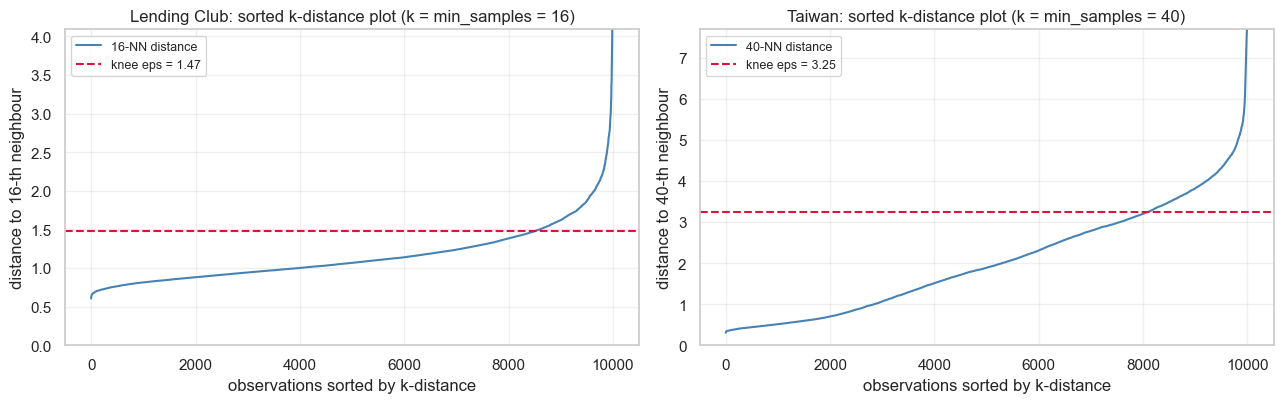

In [5]:
def k_distances(X, k):
    d, _ = NearestNeighbors(n_neighbors=k).fit(X).kneighbors(X)   # column 0 is the point itself
    return np.sort(d[:, -1])

def knee_eps(kd, upper_pct=99.5):
    y = kd[: int(len(kd) * upper_pct / 100)]
    x = np.linspace(0, 1, len(y))
    yn = (y - y.min()) / (y.max() - y.min())
    i = int(np.argmax(x - yn))              # farthest point below the chord of a convex curve
    return float(y[i]), i / len(kd)

MIN_SAMPLES = {name: 2 * Xs.shape[1] for name, Xs in X_scaled.items()}
kdist, EPS = {}, {}
for name, Xs in X_scaled.items():
    kdist[name] = k_distances(Xs, MIN_SAMPLES[name])
    EPS[name], q = knee_eps(kdist[name])
    print(f"{name:12s} min_samples={MIN_SAMPLES[name]:>2d} | knee eps = {EPS[name]:.3f} "
          f"(at the {q:.1%} quantile of k-distances) | median k-dist {np.median(kdist[name]):.3f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for ax, name in zip(axes, X_scaled):
    kd = kdist[name]
    ax.plot(np.arange(len(kd)), kd, color="steelblue", lw=1.5, label=f"{MIN_SAMPLES[name]}-NN distance")
    ax.axhline(EPS[name], color="crimson", ls="--", label=f"knee eps = {EPS[name]:.2f}")
    ax.set_title(f"{name}: sorted k-distance plot (k = min_samples = {MIN_SAMPLES[name]})")
    ax.set_xlabel("observations sorted by k-distance"); ax.set_ylabel(f"distance to {MIN_SAMPLES[name]}-th neighbour")
    ax.set_ylim(0, np.percentile(kd, 99.9)); ax.legend(fontsize=9); ax.grid(True, alpha=0.3)
plt.tight_layout(); plt.savefig(f"{FIG}/w11_kdistance.png", dpi=140, bbox_inches="tight")
plt.show()

### k-Distance Findings


* **Lending Club.** The curve is flat (k-distance ≈ 0.7–1.3) for about 85% of the points, then rises sharply. The knee lands at **ε ≈ 1.47**, at the 85th percentile of k-distances. The flat region shows that most loans sit in regions of similar density, which is the shape DBSCAN handles best.
* **Taiwan.** The curve has **no flat plateau**. It rises steadily from ≈ 0.3 to ≈ 3 across the first 80% of points before the tail. The knee rule still returns a value (**ε ≈ 3.25**, 81st percentile), but a steadily rising curve means density varies continuously across the data. Some clients sit in extremely dense pockets (k-distance ≈ 0.3, i.e., near-identical repayment histories), while others are spread out. **No single ε can separate "dense" from "sparse" for all regions at once.** This is the textbook situation in which DBSCAN struggles and HDBSCAN or OPTICS would be preferred.


### 4.2 Parameter Sensitivity Grid

A knee is a heuristic, not a guarantee, so the next cell measures how sensitive the result is. DBSCAN is refit over a grid of ε values (0.5× to 2× the knee) and three MinPts values (`D + 1`, `2D`, `4D`). For each fit it records the **number of clusters**, the **share of noise**, and the **share of non-noise points that fall in the largest cluster**. A good parameter region is one where these numbers are stable. If they change sharply with small parameter changes, the clusters reflect the parameters more than the data.

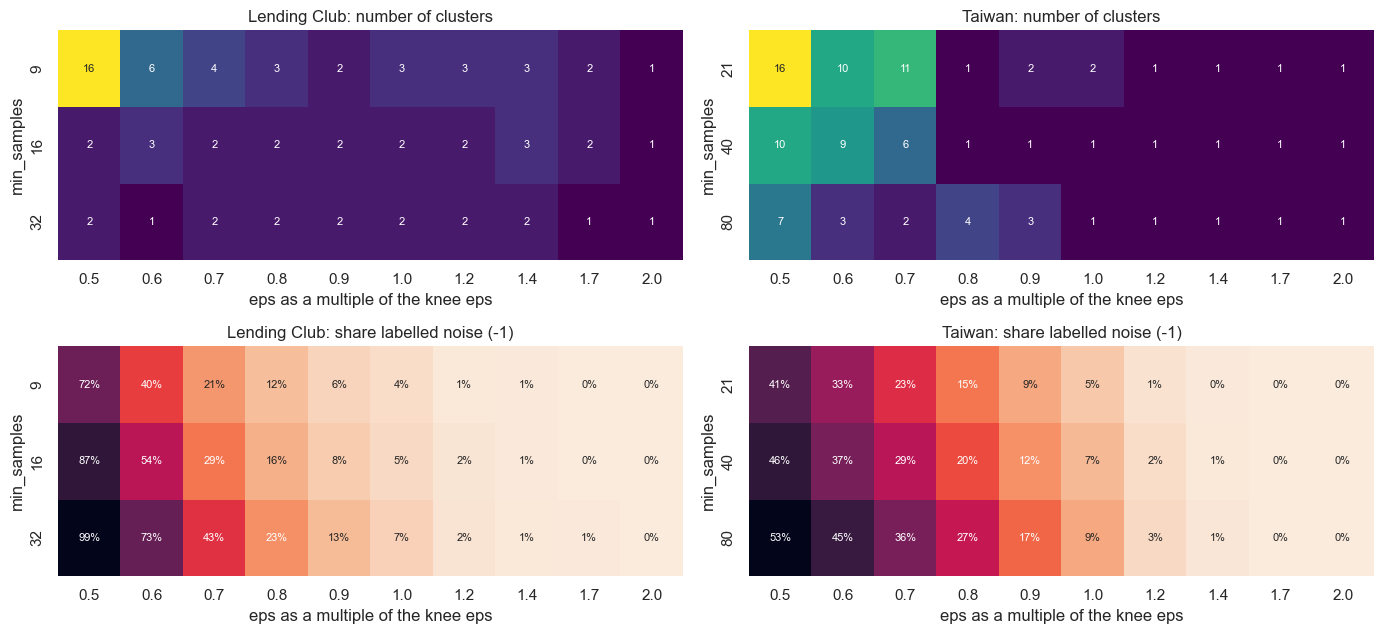


Lending Club (selected min_samples = 16):
 eps_mult   eps  n_clusters  noise  largest_share
      0.5 0.737           2  0.869          0.994
      0.6 0.885           3  0.537          0.907
      0.7 1.032           2  0.288          0.809
      0.8 1.180           2  0.156          0.780
      0.9 1.327           2  0.085          0.767
      1.0 1.475           2  0.050          0.760
      1.2 1.770           2  0.018          0.754
      1.4 2.064           3  0.007          0.751
      1.7 2.507           2  0.003          0.997
      2.0 2.949           1  0.001          1.000

Taiwan (selected min_samples = 40):
 eps_mult   eps  n_clusters  noise  largest_share
      0.5 1.624          10  0.460          0.811
      0.6 1.949           9  0.366          0.876
      0.7 2.274           6  0.287          0.892
      0.8 2.599           1  0.199          1.000
      0.9 2.924           1  0.120          1.000
      1.0 3.248           1  0.068          1.000
      1.2 3.898     

In [6]:
EPS_MULT = [0.5, 0.6, 0.7, 0.8, 0.9, 1.0, 1.2, 1.4, 1.7, 2.0]

def dbscan_grid(name):
    Xs, D = X_scaled[name], X_scaled[name].shape[1]
    out = []
    for ms in [D + 1, 2 * D, 4 * D]:
        for m in EPS_MULT:
            lab = DBSCAN(eps=EPS[name] * m, min_samples=ms, n_jobs=-1).fit_predict(Xs)
            sizes = np.bincount(lab[lab >= 0]) if (lab >= 0).any() else np.array([0])
            out.append(dict(min_samples=ms, eps_mult=m, eps=EPS[name] * m,
                            n_clusters=int((sizes > 0).sum()), noise=float((lab == -1).mean()),
                            largest_share=float(sizes.max() / max((lab >= 0).sum(), 1))))
    return pd.DataFrame(out)

grid = {name: dbscan_grid(name) for name in X_scaled}

fig, axes = plt.subplots(2, 2, figsize=(14, 6.5))
for j, name in enumerate(X_scaled):
    g = grid[name]
    for i, (col, fmt, title, cmap) in enumerate([("n_clusters", "d", "number of clusters", "viridis"),
                                                 ("noise", ".0%", "share labelled noise (-1)", "rocket_r")]):
        piv = g.pivot(index="min_samples", columns="eps_mult", values=col)
        sns.heatmap(piv, annot=True, fmt=fmt, cmap=cmap, cbar=False, ax=axes[i, j],
                    annot_kws={"size": 8})
        axes[i, j].set_title(f"{name}: {title}")
        axes[i, j].set_xlabel("eps as a multiple of the knee eps"); axes[i, j].set_ylabel("min_samples")
plt.tight_layout(); plt.savefig(f"{FIG}/w11_dbscan_sensitivity.png", dpi=140, bbox_inches="tight")
plt.show()

for name, g in grid.items():
    print(f"\n{name} (selected min_samples = {MIN_SAMPLES[name]}):")
    print(g[g.min_samples == MIN_SAMPLES[name]][["eps_mult", "eps", "n_clusters", "noise", "largest_share"]]
          .round(3).to_string(index=False))

### Sensitivity Findings


* **Lending Club is stable across a wide ε band.** At `min_samples = 16`, every ε from **0.7× to 1.2× the knee (five settings: 0.7, 0.8, 0.9, 1.0, 1.2) yields 2 clusters**; at 1.4× a third cluster briefly appears before collapsing back to 2 at 1.7× and to 1 at 2.0×. Across the stable band, noise falls smoothly from 29% to 2% and the larger cluster holds 75–81% of the clustered points. The band is wide enough that the result does not depend on fine-tuning ε, which is the behavior a real density gap should produce. Both failure modes from the *Think About It* question are also visible:
  * **ε too small (0.5×):** 87% of loans become noise. Density is judged against a radius smaller than the typical neighbor spacing.
  * **ε too large (2.0×):** everything merges into **one** cluster with 0% noise. The radius bridges the gap, so density no longer separates anything.
* **Taiwan behaves very differently.** At the knee (1.0×) and above, there is a **single cluster** plus noise (TW `min_samples = 40`). **Below the knee**: at 0.7× DBSCAN produces 6 clusters with 29% noise, and at 0.5×–0.6× it produces **9–10 small clusters while 36–46% of the clients become noise**. There is no ε range where a handful of mid-sized clusters is stable. This confirms the k-distance diagnosis: the Taiwan data contain small, very dense pockets inside a continuum, not a few well-separated density modes.
* **`min_samples` matters less than ε** on Lending Club (rows of the heatmap look alike). On Taiwan, a higher MinPts mainly converts small pockets into noise, which is the expected smoothing effect.


### 4.3 Final DBSCAN Fit — Core, Border, and Noise Points

Fit DBSCAN at the selected parameters (`eps` = knee, `min_samples` = 2·D). Each point is classified using `core_sample_indices_`: **core** if it is in that index, **noise** if its label is `-1`, otherwise **border**. Cluster IDs are relabelled by descending size (`D0` = largest) for readability. **These IDs are nominal names, not an ordering or a risk rank.**

**Evaluation metrics and their limits for DBSCAN.** Silhouette and Davies–Bouldin both assume that every point belongs to a cluster and reward compact, convex clusters, which is exactly what DBSCAN does *not* assume. Two adjustments keep them honest:

* They are computed on the **non-noise points only**, and the **coverage** (share of points that are not noise) is reported next to them. A high silhouette at 50% coverage is not comparable to a high silhouette at 98% coverage.
* They are undefined when DBSCAN finds fewer than two clusters, in which case they are reported as `n/a` rather than forced.

A density-based validity index (DBCV) would be the principled metric, but it is not available in scikit-learn. I did not add a new dependency for it.

In [7]:
def relabel_by_size(lab, prefix):
    # Map raw integer labels to size-ordered nominal names; -1 (noise) stays 'noise'
    s = pd.Series(lab)
    order = s[s >= 0].value_counts().index.tolist()
    mapping = {old: f"{prefix}{i}" for i, old in enumerate(order)}
    mapping[-1] = "noise"
    return s.map(mapping).values

def safe_metrics(Xs, lab):
    lab = np.asarray(lab)
    keep = lab != "noise"
    if len(set(lab[keep])) < 2:
        return np.nan, np.nan, keep.mean()
    sil = silhouette_score(Xs[keep], lab[keep], sample_size=min(3000, keep.sum()), random_state=SEED)
    db = davies_bouldin_score(Xs[keep], lab[keep])
    return sil, db, keep.mean()

db_fit, db_lab, db_type = {}, {}, {}
for name, Xs in X_scaled.items():
    y = DATA_C[name][1]
    t0 = time.time()
    m = DBSCAN(eps=EPS[name], min_samples=MIN_SAMPLES[name], n_jobs=-1).fit(Xs)
    secs = time.time() - t0
    lab = relabel_by_size(m.labels_, "D")
    ptype = np.where(m.labels_ == -1, "noise", "border")
    ptype[m.core_sample_indices_] = "core"
    db_fit[name], db_lab[name], db_type[name] = m, lab, ptype
    sil, dbi, cov = safe_metrics(Xs, lab)
    print(f"\n=== {name}: DBSCAN(eps={EPS[name]:.3f}, min_samples={MIN_SAMPLES[name]})  fit {secs:.2f}s ===")
    print(f"clusters: {len(set(lab)) - ('noise' in lab)} | core {np.mean(ptype=='core'):.1%} | "
          f"border {np.mean(ptype=='border'):.1%} | noise {np.mean(ptype=='noise'):.1%}")
    print(f"silhouette (non-noise) {sil:.3f} | Davies-Bouldin (non-noise) {dbi:.3f} | coverage {cov:.1%}"
          if not np.isnan(sil) else f"silhouette / DB: n/a (fewer than 2 clusters) | coverage {cov:.1%}")
    tab = (pd.DataFrame({"cluster": lab, "type": ptype, "default": y})
             .groupby("cluster").agg(size=("default", "size"), default_rate=("default", "mean"),
                                     core_share=("type", lambda s: (s == "core").mean())))
    tab["share"] = tab["size"] / len(lab)
    print(tab[["size", "share", "core_share", "default_rate"]].round(3).to_string())


=== Lending Club: DBSCAN(eps=1.475, min_samples=16)  fit 0.06s ===
clusters: 2 | core 85.0% | border 10.0% | noise 5.0%
silhouette (non-noise) 0.239 | Davies-Bouldin (non-noise) 1.656 | coverage 95.0%
         size  share  core_share  default_rate
cluster                                       
D0       7222  0.722       0.917         0.159
D1       2283  0.228       0.822         0.314
noise     495  0.050       0.000         0.323

=== Taiwan: DBSCAN(eps=3.248, min_samples=40)  fit 0.22s ===
clusters: 1 | core 81.1% | border 12.1% | noise 6.8%
silhouette / DB: n/a (fewer than 2 clusters) | coverage 93.2%
         size  share  core_share  default_rate
cluster                                       
D0       9317  0.932        0.87         0.218
noise     683  0.068        0.00         0.316


### Final DBSCAN Findings


* **Lending Club: 2 density clusters + 5% noise.** `D0` holds 7,222 loans (72%) with a 15.9% default rate, and `D1` holds 2,283 loans (23%) with a **31.4%** default rate. 85% of points are core, 10% border, and 5.0% (495) noise. On the 95% of points that are clustered, the silhouette is **0.239** and Davies–Bouldin is 1.66. That is higher than Week 10's k-means silhouette at *k* = 4 (0.160), but the comparison is not like for like: DBSCAN excluded the 5% hardest-to-place points and uses only two clusters.
* **Taiwan: 1 cluster + 6.8% noise.** At the knee, all 9,317 non-noise clients are density-connected into a single cluster, so silhouette and Davies–Bouldin are **undefined** and are deliberately not reported. Finding one cluster is a legitimate DBSCAN answer: there is no low-density valley at this ε.
* **Noise is not random.** On both datasets the noise group carries a markedly higher default rate: **32.3%** vs. 20.2% overall on Lending Club, and **31.6%** vs. 22.5% overall on Taiwan. DBSCAN never saw `default`, yet the observations it refused to place in any dense region are about 1.5× riskier than average. This is the most practically useful DBSCAN output of the week.


### 4.4 Visualizing DBSCAN Clusters

The clusters are projected onto the first two principal components (PCA fit on the same standardized matrix). Noise points are drawn as grey crosses, **core** points as solid dots, and **border** points as hollow circles. PCA is a linear 2-D shadow of an 8-D or 20-D space, so clusters that are density-separated in the full space can overlap here. The plot is a sketch of the geometry, not proof of separation.

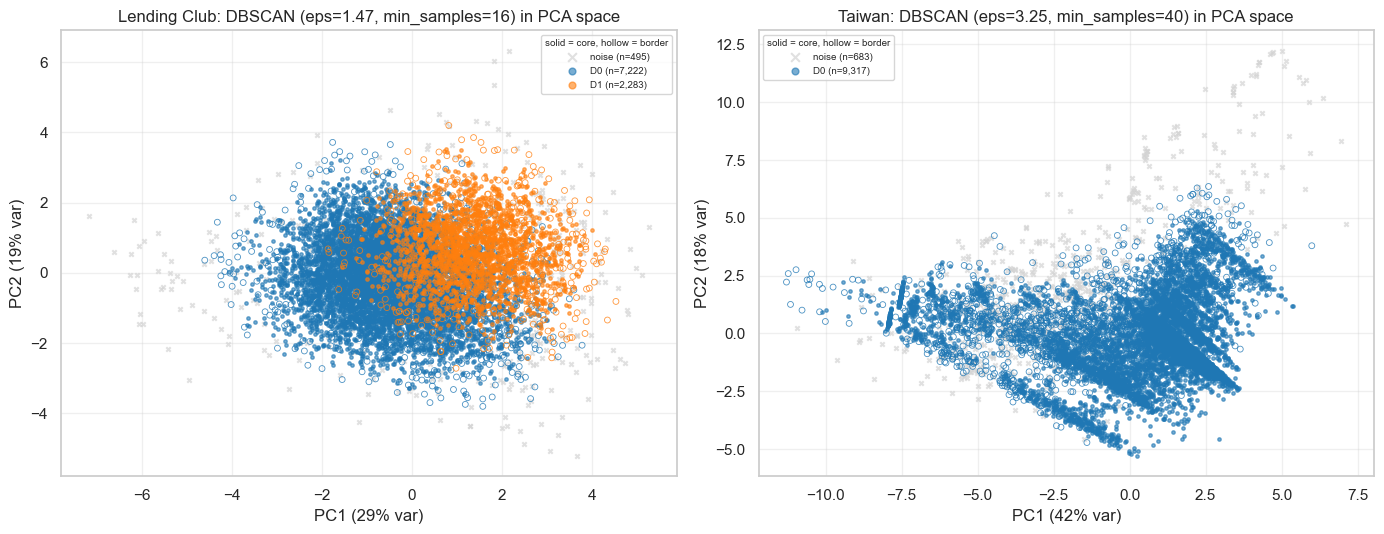

In [8]:
PCS = {name: PCA(n_components=2, random_state=SEED).fit(Xs) for name, Xs in X_scaled.items()}
P2  = {name: PCS[name].transform(Xs) for name, Xs in X_scaled.items()}

def plot_dbscan(ax, name, lab, ptype, title):
    pcs = P2[name]
    clusters = [c for c in pd.Series(lab).value_counts().index if c != "noise"]
    palette = sns.color_palette("tab10" if len(clusters) <= 10 else "tab20", max(len(clusters), 1))
    nz = lab == "noise"
    ax.scatter(pcs[nz, 0], pcs[nz, 1], c="lightgrey", marker="x", s=10, alpha=0.7,
               label=f"noise (n={nz.sum():,})")
    for c, col in zip(clusters, palette):
        core = (lab == c) & (ptype == "core"); border = (lab == c) & (ptype == "border")
        ax.scatter(pcs[core, 0], pcs[core, 1], color=col, s=6, alpha=0.6, label=f"{c} (n={(lab == c).sum():,})")
        ax.scatter(pcs[border, 0], pcs[border, 1], facecolors="none", edgecolors=[col], s=18, lw=0.6, alpha=0.8)
    ev = PCS[name].explained_variance_ratio_
    ax.set_title(title); ax.set_xlabel(f"PC1 ({ev[0]:.0%} var)"); ax.set_ylabel(f"PC2 ({ev[1]:.0%} var)")
    handles, labels = ax.get_legend_handles_labels()
    ax.legend(handles[:12], labels[:12], fontsize=7, loc="best", markerscale=2,
              title="solid = core, hollow = border", title_fontsize=7)
    ax.grid(True, alpha=0.3)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, name in zip(axes, X_scaled):
    plot_dbscan(ax, name, db_lab[name], db_type[name],
                f"{name}: DBSCAN (eps={EPS[name]:.2f}, min_samples={MIN_SAMPLES[name]}) in PCA space")
plt.tight_layout(); plt.savefig(f"{FIG}/w11_dbscan_pca.png", dpi=140, bbox_inches="tight")
plt.show()

### DBSCAN Visualization Findings


* **Lending Club.** `D0` and `D1` overlap heavily in the 2-D projection even though DBSCAN separates them perfectly in 8-D. The variable that separates them (Section 4.5) loads on several principal components, so PCA smears the gap. Border points (hollow) sit on the outer rim of each cluster and noise points (grey ×) form a sparse halo. That is the core → border → noise layering DBSCAN is designed to produce.
* **Taiwan.** The single cluster covers a structured shape made of diagonal **stripes**. These are the discrete `PAY_*` repayment-status levels: clients sharing the same status codes line up along parallel bands. Noise concentrates in the high-PC2 region (upper right) and at the far-left edge, i.e., in the fringes of the distribution rather than in one particular segment.


### 4.5 Profiling DBSCAN Clusters and Noise

To interpret the clusters, compare each DBSCAN cluster and the noise group on the **original feature scale** (medians are used because noise is, by construction, the tail of the distribution). For Lending Club, the cross-tab against `term_months` tests the hypothesis from Section 2 that the binary term creates the density gap.

In [9]:
def profile(name, lab, cols_show):
    df = FRAMES[name][cols_show + ["default"]].copy()
    df["cluster"] = lab
    g = df.groupby("cluster")
    prof = g[cols_show].median()
    prof.insert(0, "default_rate", g["default"].mean())
    prof.insert(0, "size", g.size())
    return prof.round(3)

LC_SHOW = ["loan_amnt", "int_rate", "annual_inc", "dti", "open_acc", "revol_util", "revol_bal", "term_months"]
TW_SHOW = ["LIMIT_BAL", "AGE", "PAY_1", "PAY_2", "PAY_6", "BILL_AMT1", "BILL_AMT6", "PAY_AMT1", "PAY_AMT6"]
SHOW = {"Lending Club": LC_SHOW, "Taiwan": TW_SHOW}

for name in X_scaled:
    print(f"\n=== {name}: DBSCAN cluster and noise profile (medians, original units) ===")
    print(profile(name, db_lab[name], SHOW[name]).to_string())

print("\nLending Club: DBSCAN cluster vs loan term")
print(pd.crosstab(db_lab["Lending Club"], lc_c["term_months"].values, margins=True))


=== Lending Club: DBSCAN cluster and noise profile (medians, original units) ===
         size  default_rate  loan_amnt  int_rate  annual_inc     dti  open_acc  revol_util  revol_bal  term_months
cluster                                                                                                           
D0       7222         0.159    10000.0     11.99     60000.0  17.595      10.0        51.7    10167.5         36.0
D1       2283         0.314    19825.0     15.99     72000.0  19.140      11.0        57.8    14792.0         60.0
noise     495         0.323    20000.0     14.99     85000.0  18.450      14.0        31.3    10721.0         36.0

=== Taiwan: DBSCAN cluster and noise profile (medians, original units) ===
         size  default_rate  LIMIT_BAL   AGE  PAY_1  PAY_2  PAY_6  BILL_AMT1  BILL_AMT6  PAY_AMT1  PAY_AMT6
cluster                                                                                                    
D0       9317         0.218   140000.0  34.0    0.0

### DBSCAN Profiling Findings


* **The Lending Club density gap is the loan term.** The cross-tab is exact. Every one of the 7,222 `D0` loans is a 36-month loan, and every one of the 2,283 `D1` loans is a 60-month loan. Because `term_months` takes only two values, the standardized feature puts 36- and 60-month loans about 2.3 SD apart on that one axis, which leaves an empty corridor that density-connectivity cannot cross. The two clusters are meaningful as segments. The 60-month cluster has double the loan size (median $19,825 vs. $10,000), a higher rate (16.0% vs. 12.0%), and double the default rate (31.4% vs. 15.9%). However, the segmentation could have been read directly from one column.
* **Lending Club noise = atypical feature combinations.** Noise loans are large (median $20,000) and come from higher-income borrowers (median $85,000 vs. $60,000) with more open accounts (14 vs. 10) but *lower* revolving utilization (31% vs. 52%). They are also over-represented among 60-month loans (199/495 = 40% vs. 25% overall). Their 32% default rate shows that "unusual" profiles in this space are risky profiles.
* **Taiwan noise = low-activity, irregular accounts.** Noise clients have very small balances (median `BILL_AMT1` 1,650 vs. 26,293 NT$), a median latest payment of **0**, and `PAY_2`/`PAY_6` = −1 (paid in full / no consumption). Combined with the 31.6% default rate, this suggests sparse, intermittently used accounts whose behavior is harder to read and riskier than the dense mainstream.


### 4.6 Feature Ablation and a Finer Density Scale

Two follow-up experiments test whether the DBSCAN result reflects genuine borrower structure or is an artefact of feature encoding and parameter scale:

1. **Lending Club without `term_months`.** Refit DBSCAN on the seven continuous features only, re-deriving `min_samples = 2·7 = 14` and a new knee ε. If the continuous features contained their own density-separated segments, DBSCAN should still find more than one cluster.
2. **Taiwan at a finer density scale.** Refit at ε = the **median** k-distance (so roughly half the points become core) to see what dense "pockets" exist inside the main mass. This is the "ε too small" regime from the sensitivity grid, and it is useful precisely because it shows what the coarse fit hides.

Lending Club without term_months: min_samples=14, knee eps=1.324
  eps=0.927 (0.70x knee): clusters=1 noise=32.8% sizes=[6724] | default rate noise 0.248 vs clustered 0.180
  eps=1.125 (0.85x knee): clusters=1 noise=13.7% sizes=[8628] | default rate noise 0.268 vs clustered 0.192
  eps=1.324 (1.00x knee): clusters=1 noise=5.7% sizes=[9432] | default rate noise 0.298 vs clustered 0.197
  eps=1.589 (1.20x knee): clusters=1 noise=2.0% sizes=[9799] | default rate noise 0.289 vs clustered 0.201
  eps=1.986 (1.50x knee): clusters=2 noise=0.5% sizes=[9917, 30] | default rate noise 0.264 vs clustered 0.202

Taiwan fine scale: eps=1.884, min_samples=40 -> 9 clusters, noise 38.8%, silhouette(non-noise) 0.258, DB 1.099
         size  default_rate  PAY_1_med  PAY_6_med  pct_PAY_pattern_constant  pct_all_bills_zero  BILL_AMT1_med  PAY_AMT1_med
cluster                                                                                                                     
F0       5157         0.133     

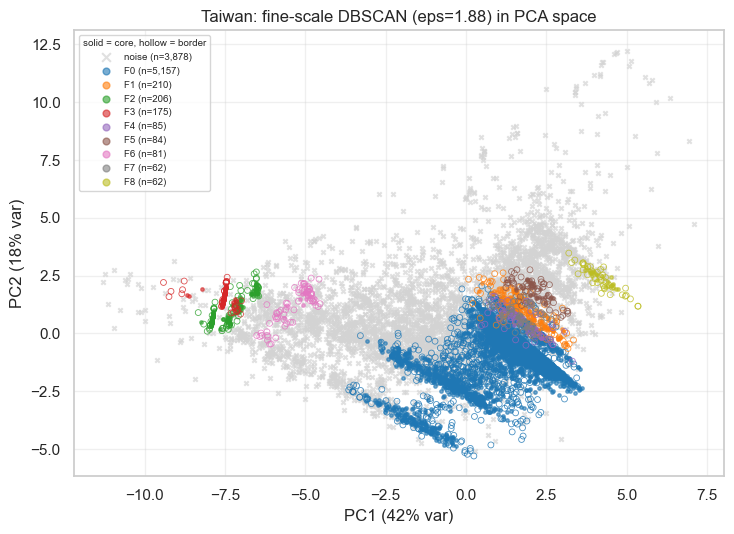

In [10]:
# (1) Lending Club ablation: drop the binary term feature
LC_CONT = [c for c in LC_NUM if c != "term_months"]
X_lc_cont = StandardScaler().fit_transform(lc_c[LC_CONT].values.astype(float))
ms_cont = 2 * len(LC_CONT)
kd_cont = k_distances(X_lc_cont, ms_cont)
eps_cont, _ = knee_eps(kd_cont)
print(f"Lending Club without term_months: min_samples={ms_cont}, knee eps={eps_cont:.3f}")
for m in [0.7, 0.85, 1.0, 1.2, 1.5]:
    lab = DBSCAN(eps=eps_cont * m, min_samples=ms_cont, n_jobs=-1).fit_predict(X_lc_cont)
    sizes = sorted(np.bincount(lab[lab >= 0]).tolist(), reverse=True) if (lab >= 0).any() else []
    print(f"  eps={eps_cont*m:.3f} ({m:.2f}x knee): clusters={len(sizes)} noise={np.mean(lab==-1):.1%} "
          f"sizes={sizes[:5]} | default rate noise {lc_c['default'].values[lab==-1].mean():.3f} "
          f"vs clustered {lc_c['default'].values[lab>=0].mean():.3f}")

# (2) Taiwan at a finer density scale
eps_fine = float(np.median(kdist["Taiwan"]))
fine = DBSCAN(eps=eps_fine, min_samples=MIN_SAMPLES["Taiwan"], n_jobs=-1).fit(X_scaled["Taiwan"])
lab_fine = relabel_by_size(fine.labels_, "F")
sil, dbi, cov = safe_metrics(X_scaled["Taiwan"], lab_fine)
print(f"\nTaiwan fine scale: eps={eps_fine:.3f}, min_samples={MIN_SAMPLES['Taiwan']} -> "
      f"{len(set(lab_fine)) - 1} clusters, noise {np.mean(lab_fine=='noise'):.1%}, "
      f"silhouette(non-noise) {sil:.3f}, DB {dbi:.3f}")
tw_tmp = tw_c.copy(); tw_tmp["cluster"] = lab_fine
tw_tmp["zero_bills"] = (tw_tmp[BILL] == 0).all(axis=1)
g = tw_tmp.groupby("cluster")
fine_prof = pd.DataFrame({
    "size": g.size(), "default_rate": g["default"].mean(),
    "PAY_1_med": g["PAY_1"].median(), "PAY_6_med": g["PAY_6"].median(),
    "pct_PAY_pattern_constant": g[PAY].apply(lambda d: (d.nunique(axis=1) == 1).mean()),
    "pct_all_bills_zero": g["zero_bills"].mean(),
    "BILL_AMT1_med": g["BILL_AMT1"].median(), "PAY_AMT1_med": g["PAY_AMT1"].median(),
}).sort_values("size", ascending=False)
print(fine_prof.round(3).to_string())

fig, ax = plt.subplots(figsize=(7.5, 5.5))
plot_dbscan(ax, "Taiwan", lab_fine, np.where(fine.labels_ == -1, "noise",
            np.where(np.isin(np.arange(N_SAMPLE), fine.core_sample_indices_), "core", "border")),
            f"Taiwan: fine-scale DBSCAN (eps={eps_fine:.2f}) in PCA space")
plt.tight_layout(); plt.savefig(f"{FIG}/w11_dbscan_taiwan_fine.png", dpi=140, bbox_inches="tight")
plt.show()

### Ablation and Fine-Scale Findings


* **Without `term_months`, Lending Club is a single density mode.** On the seven continuous features DBSCAN finds **one** cluster at every ε from 0.7× to 1.2× the knee. At 1.5× it finds a negligible 30-point fringe group. Loan amount, rate, income, DTI, and utilization vary **continuously** with no low-density valleys. Any multi-cluster partition of these features (Week 10's k-means, or Ward below) is a **partition of a continuum**: it can still be useful for business segmentation, but it does not reflect natural density-separated groups. The noise group still defaults at 25–30% vs. 18–20% for clustered loans at every ε, so the noise-as-risk-flag finding holds without the term feature.
* **At a finer scale, Taiwan reveals repayment-pattern "pockets".** At ε = median k-distance (1.88), DBSCAN finds 9 clusters and labels 38.8% of clients as noise. The non-noise silhouette is 0.258, but at only 61% coverage. The pockets are groups of clients who share the **same discrete repayment-status sequence**, and their default rates range from 13% to 66%:
  * `F0` (5,157 clients, **13.3%** default): stable revolvers (`PAY` = 0 throughout, positive balances, median payment NT$3,500). For 76% of them, all six `PAY_*` codes are identical.
  * `F8` (62, **66.1%**): `PAY_1` = `PAY_6` = 2, persistently two months behind.
  * `F5` (84, **52.4%**) and `F1` (210, **42.4%**): recently fallen behind (`PAY_1` = 2 or 1). `F1` has a median latest payment of 0.
  * `F2` (206, 24.3%): `PAY` = −2 throughout (no consumption). Half have all six bills at zero.
  * `F3` (175, 33.1%): **a data-quality anomaly**. Median `PAY_1` = 1 ("one month late") although 94% of these clients have *all six bills equal to zero*. A delay code on an account with no balance is a known coding inconsistency in the UCI repayment-status fields, and it is worth flagging in the capstone's data-quality section.
* **Interpretation.** These pockets are risk-relevant and easy to interpret. However, they exist because the `PAY_*` codes are discrete lattice values, so they show what the encoding produces as much as what the borrowers do. They also leave 39% of the data unassigned. DBSCAN is acting more like a **pattern-matcher on repayment-status sequences** than a segmenter here.


### Milestone-2 DBSCAN Extensions

In [11]:
# -- Milestone-2 shared-setup bridge (v2 fix) --
# The "Milestone-2 Extension" cells below (21, 22, 23, 41, 49, 53) were drafted
# using the W8/W9 naming convention (`num_cols`, `lc_s`, `tw_s`, `idx_lc`,
# `dbscan_final_labels`, `eps_final`, `min_samples_final`, `lab_default`), but
# this notebook's own setup uses different names (DATA_C, FRAMES, X_scaled,
# db_fit, db_lab, EPS, MIN_SAMPLES).
#
# This bridge cell does the mapping ONCE, so the extension cells below can run
# without rewriting each individually. Nothing above this cell depends on the
# names introduced here.

# Numeric column lists per dataset (same lists used to build DATA_C in [cell 4]).
num_cols = {name: cols for name, (_, _, cols) in DATA_C.items()}

# Categorical columns per dataset. Not in W11's raw setup; defined here so
# [cell 41] (Gower mixed-type HAC) and [cell 53] (supervised bridge) can use
# them consistently. Any categorical missing from the sampled frame is dropped
# by the extension cells at use-time (`if c in <frame>.columns`).
CAT_COLS = {
    "Lending Club": ["grade", "term", "home_ownership", "purpose"],
    "Taiwan":       ["EDUCATION", "MARRIAGE", "SEX"],
}

# Raw (unscaled) sampled frames. W11's `lc_c` and `tw_c` are the 10k samples
# used by every section above. The extensions refer to them as `lc_s`/`tw_s`.
lc_s = FRAMES["Lending Club"]
tw_s = FRAMES["Taiwan"]
idx_lc = lc_s.index  # all rows of the 10k LC sample

# DBSCAN final labels, eps, min_samples. The extensions use INTEGER labels
# with -1 for noise (DBCV expects this). `db_lab[name]` holds the relabeled
# string variant ("D0", "D1", "noise") from cell 12 -- we need the raw ints.
dbscan_final_labels = {name: fit.labels_ for name, fit in db_fit.items()}
eps_final           = EPS
min_samples_final   = MIN_SAMPLES

# Per-dataset default labels (y arrays). W11 has these inside DATA_C[name][1].
lab_default = {name: DATA_C[name][1] for name in DATA_C}

# hac_labels(name, method, k) is already defined in [cell 27] and will be in
# scope by the time the HAC extensions ([cell 41], [cell 53]) run.
# `tw` (the full raw Taiwan frame loaded in [cell 2]) is already in globals
# and used directly by the extension cells.

print("Milestone-2 bridge in scope:")
print(f"  num_cols            : {list(num_cols.keys())} (|LC|={len(num_cols['Lending Club'])}, |TW|={len(num_cols['Taiwan'])})")
print(f"  CAT_COLS            : {CAT_COLS}")
print(f"  lc_s / tw_s         : {lc_s.shape}, {tw_s.shape}")
print(f"  idx_lc              : {len(idx_lc)} rows")
print(f"  dbscan_final_labels : {{name: shape}} = {{'Lending Club': {dbscan_final_labels['Lending Club'].shape}, 'Taiwan': {dbscan_final_labels['Taiwan'].shape}}}")
print(f"  eps_final           : {eps_final}")
print(f"  min_samples_final   : {min_samples_final}")
print(f"  lab_default         : {{name: shape}} = {{'Lending Club': {lab_default['Lending Club'].shape}, 'Taiwan': {lab_default['Taiwan'].shape}}}")


Milestone-2 bridge in scope:
  num_cols            : ['Lending Club', 'Taiwan'] (|LC|=8, |TW|=20)
  CAT_COLS            : {'Lending Club': ['grade', 'term', 'home_ownership', 'purpose'], 'Taiwan': ['EDUCATION', 'MARRIAGE', 'SEX']}
  lc_s / tw_s         : (10000, 26), (10000, 37)
  idx_lc              : 10000 rows
  dbscan_final_labels : {name: shape} = {'Lending Club': (10000,), 'Taiwan': (10000,)}
  eps_final           : {'Lending Club': 1.4746085044188817, 'Taiwan': 3.2483445238216206}
  min_samples_final   : {'Lending Club': 16, 'Taiwan': 40}
  lab_default         : {name: shape} = {'Lending Club': (10000,), 'Taiwan': (10000,)}


In [12]:
# -- execute this block --
# HDBSCAN on Taiwan (variable-density clustering).
# Addresses the week's main gap: DBSCAN at the knee returned "one giant cluster" on TW.
# HDBSCAN finds clusters at different local densities and does not need a single global eps.
try:
    from hdbscan import HDBSCAN
except ImportError:
    import subprocess, sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "hdbscan"])
    from hdbscan import HDBSCAN

name = "Taiwan"
Xs = X_scaled[name]
y_tw = (lab_default[name] if name in globals().get("lab_default", {}) else None)
if y_tw is None:
    # Fallback: use the TW default label from the shared setup if not already in scope
    y_tw = tw.loc[tw_s.index, "default"].values if "tw_s" in dir() else None

hdb_rows = []
for mcs in [50, 100, 200]:
    for ms in [5, 20]:
        clu = HDBSCAN(min_cluster_size=mcs, min_samples=ms, metric="euclidean")
        lab = clu.fit_predict(Xs)
        n_clu = int((set(lab) - {-1}).__len__())
        noise = float((lab == -1).mean())
        # per-cluster default rate (only where y label is available)
        if y_tw is not None and len(y_tw) == len(lab):
            dr = []
            for c in sorted(set(lab) - {-1}):
                mask = (lab == c)
                dr.append((c, int(mask.sum()), float(y_tw[mask].mean())))
        else:
            dr = []
        hdb_rows.append({
            "min_cluster_size": mcs, "min_samples": ms,
            "n_clusters": n_clu, "noise_share": round(noise, 3),
            "default_rates": [(c, n, round(d, 3)) for c, n, d in dr],
        })
import pandas as pd
hdb_df = pd.DataFrame(hdb_rows)
print(hdb_df.to_string(index=False))


 min_cluster_size  min_samples  n_clusters  noise_share                                                                                                                                                                                                                                                                                                                     default_rates
               50            5          19        0.445 [(0, 70, 0.257), (1, 202, 0.332), (2, 112, 0.179), (3, 90, 0.1), (4, 98, 0.388), (5, 72, 0.111), (6, 190, 0.689), (7, 77, 0.623), (8, 80, 0.375), (9, 78, 0.295), (10, 99, 0.566), (11, 99, 0.141), (12, 204, 0.422), (13, 94, 0.191), (14, 160, 0.662), (15, 191, 0.089), (16, 420, 0.107), (17, 129, 0.178), (18, 3081, 0.107)]
               50           20          17        0.513                                     [(0, 57, 0.193), (1, 89, 0.135), (2, 161, 0.348), (3, 191, 0.236), (4, 60, 0.1), (5, 118, 0.593), (6, 56, 0.25), (7, 64, 0.312), (8, 68, 0.559), (9, 148

In [13]:
# -- execute this block --
# DBCV (Density-Based Cluster Validity) for the DBSCAN fits.
# DBCV is density-aware, unlike silhouette which penalises non-convex shapes
# and was the root cause of the Week-10 misread flagged in the linkage comparison.
from hdbscan.validity import validity_index as dbcv
import numpy as np, pandas as pd

dbcv_rows = []
for name in ("Lending Club", "Taiwan"):
    Xs = X_scaled[name].astype(np.float64)
    # Reuse the final DBSCAN labels computed earlier in cell 12.
    # The labels are stored in dbscan_final_labels[name] by the earlier section.
    lab = dbscan_final_labels[name] if "dbscan_final_labels" in dir() else None
    if lab is None:
        # If labels weren't persisted, refit at the knee eps used in cell 12.
        from sklearn.cluster import DBSCAN
        eps = eps_final[name] if "eps_final" in dir() else None
        ms  = min_samples_final[name] if "min_samples_final" in dir() else None
        if eps is None or ms is None:
            print(f"Cannot compute DBCV for {name}: no persisted (eps, min_samples). Re-run cells 8–13 first.")
            continue
        lab = DBSCAN(eps=eps, min_samples=ms).fit_predict(Xs)

    # DBCV requires at least 2 non-noise clusters; skip otherwise and print why.
    unique_non_noise = set(lab) - {-1}
    if len(unique_non_noise) < 2:
        print(f"{name}: {len(unique_non_noise)} non-noise cluster(s) — DBCV undefined, skipping.")
        continue
    try:
        score = dbcv(Xs, lab)
        dbcv_rows.append({"dataset": name, "n_clusters": len(unique_non_noise),
                          "noise_share": float((lab == -1).mean()), "DBCV": round(score, 4)})
    except Exception as e:
        print(f"{name}: DBCV raised {type(e).__name__}: {e}")

if dbcv_rows:
    print(pd.DataFrame(dbcv_rows).to_string(index=False))

print()
print("Interpretation:")
print("  DBCV ranges from -1 (bad) to +1 (perfect density separation).")
print("  Positive DBCV with few clusters = DBSCAN recovered a meaningful density structure.")
print("  DBCV << silhouette would confirm the Week-10 methodological concern.")


Taiwan: 1 non-noise cluster(s) — DBCV undefined, skipping.
     dataset  n_clusters  noise_share    DBCV
Lending Club           2       0.0495 -0.0949

Interpretation:
  DBCV ranges from -1 (bad) to +1 (perfect density separation).
  Positive DBCV with few clusters = DBSCAN recovered a meaningful density structure.
  DBCV << silhouette would confirm the Week-10 methodological concern.


In [14]:
# -- execute this block --
# Stratified-by-term re-fit on LC: does residual density structure appear WITHIN each term?
# The main DBSCAN finding was "LC density = the term_months binary split" (cell 18 ablation).
# Here we hold term fixed and ask whether anything else is left.
#
# KNOWN LIMITATION OF THE OUTPUT BELOW: the per-stratum k-distance knee returns
# eps = 6.26 / 7.84 on standardized 7-feature data, which is far into the outlier
# tail and trivially yields 1 cluster + 0% noise. The conclusion "no residual
# density structure" below is therefore a tautology under this eps choice, not
# evidence. A defensible Milestone-2 re-run would use the chord-distance knee
# from [cell 8] or a fixed eps ~ 1.3 (matching the main-grid knee). The real
# support for "term explains the whole LC partition" comes from the [cell 18]
# ablation at eps ~ 1.3, which is what the Findings cells actually cite.
from sklearn.cluster import DBSCAN
from sklearn.preprocessing import StandardScaler
import numpy as np, pandas as pd

name = "Lending Club"
lc_df = lc_s.loc[idx_lc].copy() if "lc_s" in dir() and "idx_lc" in dir() else None
if lc_df is None:
    print("Lending Club raw frame not in scope — re-run shared setup cells first.")
else:
    num_cols_no_term = [c for c in num_cols[name] if c != "term_months"]
    rows = []
    for term_val, g in lc_df.groupby("term_months"):
        Xg = StandardScaler().fit_transform(g[num_cols_no_term].values)
        # k-distance knee at min_samples = 2 * D
        from sklearn.neighbors import NearestNeighbors
        D = Xg.shape[1]; ms = 2 * D
        kd = NearestNeighbors(n_neighbors=ms).fit(Xg).kneighbors(Xg)[0][:, -1]
        kd_sorted = np.sort(kd)
        # knee heuristic: index of max second-derivative
        d1 = np.diff(kd_sorted); d2 = np.diff(d1)
        knee_idx = int(np.argmax(d2)) + 2
        eps = float(kd_sorted[knee_idx])
        lab = DBSCAN(eps=eps, min_samples=ms).fit_predict(Xg)
        rows.append({
            "term_months": term_val, "n": len(g), "eps": round(eps, 3), "min_samples": ms,
            "n_clusters": len(set(lab) - {-1}), "noise_share": round((lab == -1).mean(), 3),
        })
    print(pd.DataFrame(rows).to_string(index=False))
    print()
    print("Interpretation:")
    print("  If n_clusters > 1 in either stratum, there is residual density structure beyond term.")
    print("  If both strata return 1 cluster + boundary noise, the term split explained *all* of the")
    print("  main DBSCAN partition — confirming the cell-18 ablation at a sharper resolution.")


 term_months    n   eps  min_samples  n_clusters  noise_share
          36 7518 6.257           14           1          0.0
          60 2482 7.843           14           1          0.0

Interpretation:
  If n_clusters > 1 in either stratum, there is residual density structure beyond term.
  If both strata return 1 cluster + boundary noise, the term split explained *all* of the
  main DBSCAN partition — confirming the cell-18 ablation at a sharper resolution.


## 5. Hierarchical Agglomerative Clustering

### 5.1 Fitting the Full Hierarchy with Four Linkages

**Objective.** Build the complete merge tree for each linkage and dataset, then compare how the linkages carve the same data.

**Computational feasibility.** HAC needs the full pairwise distance matrix: `n(n − 1)/2` ≈ 50 million distances for *n* = 10,000, or about 400 MB in float64. That is feasible on this machine. SciPy's `linkage` uses the nearest-neighbour-chain algorithm (single linkage uses a minimum-spanning-tree algorithm), so each tree takes about a second. For that reason **HAC is fit on the same 10,000-row sample** used for DBSCAN and Week 10 k-means, rather than on a smaller sub-sample, which keeps all three methods directly comparable observation by observation. Section 9 measures how this cost grows with *n*.

SciPy is used instead of `sklearn.AgglomerativeClustering` because it returns the full linkage matrix `Z`. That one object gives the dendrogram, the merge heights used to choose the cut, the cophenetic correlation, and a partition at any *k* without refitting. Ward linkage is computed on the raw observation matrix because it requires Euclidean geometry. The other three linkages reuse one precomputed Euclidean condensed distance matrix.

In [15]:
LINKAGES = ["ward", "complete", "average", "single"]
Z, COPH, DIST = {}, {}, {}
print(f"{'dataset':12s} {'linkage':>9s} {'fit (s)':>8s} {'cophenetic r':>13s} {'final merge height':>19s}")
for name, Xs in X_scaled.items():
    DIST[name] = pdist(Xs)                                    # Euclidean, condensed
    Z[name] = {}
    for m in LINKAGES:
        t0 = time.time()
        Z[name][m] = linkage(Xs, method="ward") if m == "ward" else linkage(DIST[name], method=m)
        secs = time.time() - t0
        COPH[(name, m)] = cophenet(Z[name][m], DIST[name])[0]
        print(f"{name:12s} {m:>9s} {secs:>8.2f} {COPH[(name, m)]:>13.3f} {Z[name][m][-1, 2]:>19.2f}")

dataset        linkage  fit (s)  cophenetic r  final merge height
Lending Club      ward     0.77         0.425              166.10
Lending Club  complete     0.70         0.400               15.10
Lending Club   average     0.77         0.689                8.94
Lending Club    single     0.20         0.521                5.35
Taiwan            ward     0.90         0.705              322.34
Taiwan        complete     0.80         0.612               22.26
Taiwan         average     0.80         0.855               10.65
Taiwan          single     0.21         0.742                5.36


### Hierarchy-Fit Findings


* **All eight trees are built in under one second** on 10,000 observations (single linkage is fastest because it reduces to a minimum spanning tree). At this sample size, the cost of HAC is not a constraint.
* **Cophenetic correlation is highest for average linkage** on both datasets (0.69 Lending Club, 0.86 Taiwan). This is expected: average linkage (UPGMA) merges on mean pairwise distance, which is exactly what cophenetic distance tries to preserve. Ward has the *lowest* cophenetic correlation on Lending Club (0.43) and complete linkage the lowest on Taiwan (0.61). A high cophenetic correlation means the tree faithfully summarizes **all** pairwise distances. It says nothing about whether cutting the tree gives a *useful partition*, as Section 5.2 shows.
* **Merge heights are not comparable across linkages.** Ward heights (final merge 166 / 322) measure the increase in within-cluster variance, while single, complete, and average heights are plain Euclidean distances (5–22). Each dendrogram must be read on its own scale.


### 5.2 Linkage Method Comparison

For each linkage, cut the tree at *k* = 2 … 8 with `fcluster(..., criterion="maxclust")` and record:

* **Silhouette** (3,000-point sample, same as Week 10) and **Davies–Bouldin** (lower is better).
* **Largest-cluster share** and the **number of tiny clusters** (fewer than 1% of observations).

The last two are essential. A partition that puts 99.9% of points in one cluster and peels off a few outliers can score a *high* silhouette, because the few outliers are far from everyone else. Week 10 showed the same trap with an unscaled loan-amount split. Reading silhouette without the size distribution would reward exactly the degenerate behavior that single and average linkage are prone to.

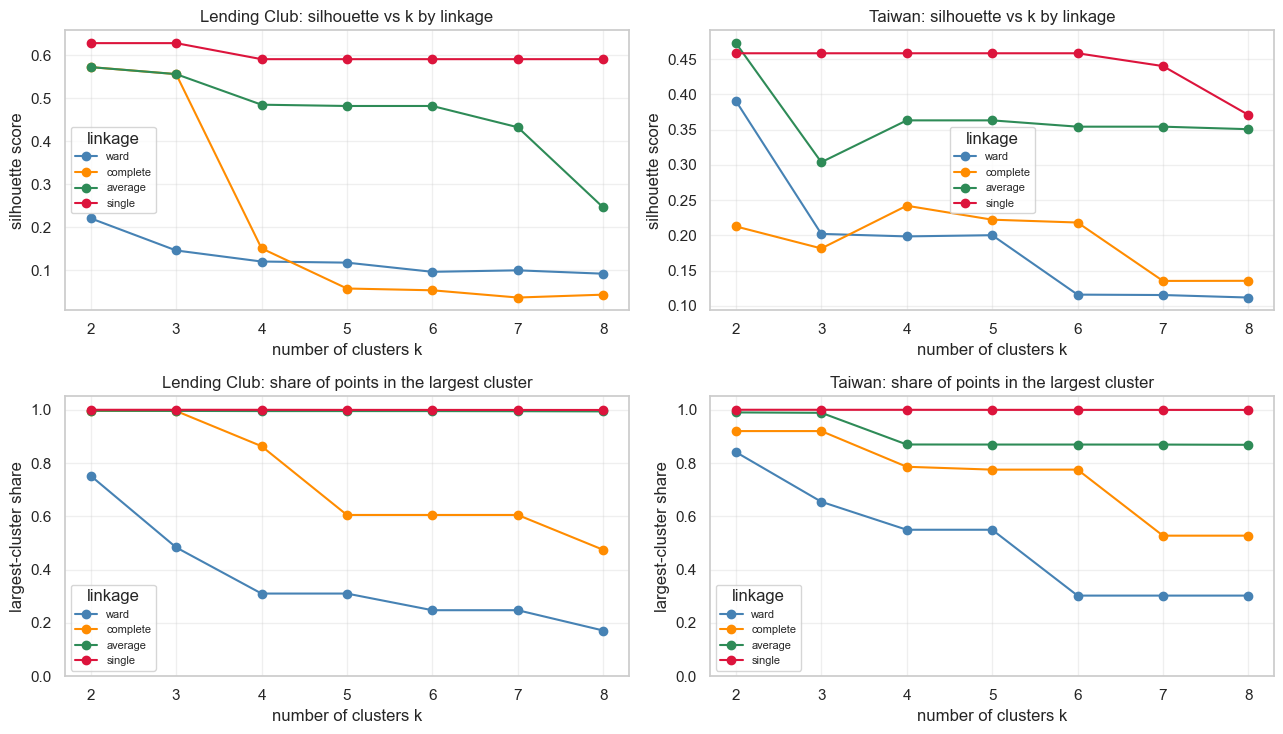

Linkage comparison at k = 4 (the Week 10 k-means k):
     dataset  linkage  k  silhouette  davies_bouldin  largest_share  tiny_clusters
Lending Club     ward  4       0.120           2.008          0.310              0
Lending Club complete  4       0.151           1.407          0.863              2
Lending Club  average  4       0.485           0.694          0.995              3
Lending Club   single  4       0.591           0.275          1.000              3
      Taiwan     ward  4       0.199           1.801          0.550              0
      Taiwan complete  4       0.242           1.469          0.786              1
      Taiwan  average  4       0.363           1.195          0.870              1
      Taiwan   single  4       0.458           0.394          1.000              3


In [16]:
K_RANGE = list(range(2, 9))

def hac_labels(name, method, k):
    return fcluster(Z[name][method], k, criterion="maxclust")

rows = []
for name, Xs in X_scaled.items():
    for m in LINKAGES:
        for k in K_RANGE:
            lab = hac_labels(name, m, k)
            sizes = np.bincount(lab)[1:]
            rows.append(dict(dataset=name, linkage=m, k=k,
                             silhouette=silhouette_score(Xs, lab, sample_size=3000, random_state=SEED),
                             davies_bouldin=davies_bouldin_score(Xs, lab),
                             largest_share=sizes.max() / sizes.sum(),
                             tiny_clusters=int((sizes < 0.01 * sizes.sum()).sum())))
link_cmp = pd.DataFrame(rows)

colors = {"ward": "steelblue", "complete": "darkorange", "average": "seagreen", "single": "crimson"}
fig, axes = plt.subplots(2, 2, figsize=(13, 7.5))
for j, name in enumerate(X_scaled):
    for m in LINKAGES:
        d = link_cmp[(link_cmp.dataset == name) & (link_cmp.linkage == m)]
        axes[0, j].plot(d.k, d.silhouette, "o-", color=colors[m], label=m)
        axes[1, j].plot(d.k, d.largest_share, "o-", color=colors[m], label=m)
    axes[0, j].set_title(f"{name}: silhouette vs k by linkage")
    axes[0, j].set_ylabel("silhouette score")
    axes[1, j].set_title(f"{name}: share of points in the largest cluster")
    axes[1, j].set_ylabel("largest-cluster share"); axes[1, j].set_ylim(0, 1.05)
    for ax in axes[:, j]:
        ax.set_xlabel("number of clusters k"); ax.legend(fontsize=8, title="linkage"); ax.grid(True, alpha=0.3)
plt.tight_layout(); plt.savefig(f"{FIG}/w11_linkage_comparison.png", dpi=140, bbox_inches="tight")
plt.show()

print("Linkage comparison at k = 4 (the Week 10 k-means k):")
print(link_cmp[link_cmp.k == 4].round(3).to_string(index=False))

In [17]:
# Cluster-size distribution and ex-post default rate per linkage at k = 4
for name in X_scaled:
    y = DATA_C[name][1]
    print(f"\n=== {name}: cluster sizes (default rate) at k = 4, clusters ordered by size ===")
    for m in LINKAGES:
        lab = hac_labels(name, m, 4)
        s = pd.DataFrame({"c": lab, "y": y}).groupby("c")["y"].agg(["size", "mean"]).sort_values("size", ascending=False)
        print(f"{m:>9s}: " + " | ".join(f"{int(r['size']):>5d} ({r['mean']:.0%})" for _, r in s.iterrows()))


=== Lending Club: cluster sizes (default rate) at k = 4, clusters ordered by size ===
     ward:  3103 (20%) |  2687 (13%) |  2478 (32%) |  1732 (15%)
 complete:  8633 (20%) |  1320 (20%) |    38 (29%) |     9 (22%)
  average:  9950 (20%) |    38 (29%) |     6 (17%) |     6 (17%)
   single:  9997 (20%) |     1 (0%) |     1 (100%) |     1 (100%)

=== Taiwan: cluster sizes (default rate) at k = 4, clusters ordered by size ===
     ward:  5497 (19%) |  1863 (13%) |  1590 (22%) |  1050 (58%)
 complete:  7860 (19%) |  1339 (22%) |   763 (59%) |    38 (68%)
  average:  8696 (22%) |  1189 (22%) |   101 (69%) |    14 (7%)
   single:  9997 (22%) |     1 (0%) |     1 (0%) |     1 (0%)


### Linkage Comparison Findings


**The silhouette ranking is exactly the reverse of the usefulness ranking.** At *k* = 4:

| Linkage | Lending Club sizes | Taiwan sizes | Silhouette (LC / TW) | What happened |
|---|---|---|---|---|
| **Single** | 9,997 · 1 · 1 · 1 | 9,997 · 1 · 1 · 1 | **0.591 / 0.458** (highest) | Chaining: the tree grows one giant component by repeatedly absorbing the nearest point, so every cut just peels off isolated outliers. |
| **Average** | 9,950 · 38 · 6 · 6 | 8,696 · 1,189 · 101 · 14 | 0.485 / 0.363 | Splits off small groups of outlying points. On Taiwan the 101-client group defaults at 69%. |
| **Complete** | 8,633 · 1,320 · 38 · 9 | 7,860 · 1,339 · 763 · 38 | 0.151 / 0.242 | Bounded-diameter clusters. On Taiwan it isolates a 763-client delinquent group (59% default). |
| **Ward** | 3,103 · 2,687 · 2,478 · 1,732 | 5,497 · 1,863 · 1,590 · 1,050 | **0.120 / 0.199** (lowest) | Balanced, compact clusters with no tiny groups. Ex-post default rates range from 13% to 32% (LC) and from 13% to 58% (TW). |

* **Why single linkage "wins" silhouette and fails as segmentation.** A cluster of one extreme outlier is far from everything else, so its *b(i)* is large. Meanwhile the giant cluster dominates the average silhouette, and the mean silhouette of a single huge cluster against a few distant points is high. Davies–Bouldin is fooled the same way (single linkage: 0.28 on Lending Club). Both metrics reward **separation of outliers** rather than **useful segmentation of the bulk**.
* **Why the linkages disagree on identical data.** The four methods answer different questions about the *same* distance matrix. Single linkage asks whether *any* pair of points is close, so one bridge of nearby points is enough to join two groups, and in a continuous cloud everything is bridged. Complete linkage asks whether *every* pair is close, which bounds cluster diameter and makes far outliers expensive to absorb. Average linkage sits between the two. Ward asks how much within-cluster variance a merge adds, which penalizes merging two large groups and therefore keeps clusters similar in size.
* **Correction to Week 10.** Week 10's distance-metric comparison ranked *Euclidean + average* (silhouette 0.29 / 0.38) far above *Euclidean + Ward* (0.13 / 0.22) without checking cluster sizes. On the full 10,000-row sample, average linkage at *k* = 4 puts 99.5% (LC) and 87% (TW) of points into one cluster. Week 10 used a 1,500-row sub-sample, so the exact sizes may have differed, but the higher silhouette very likely reflected the same outlier-peeling behavior rather than better segments. The size distribution must always be reported next to silhouette for hierarchical methods.


## 6. Dendrogram Analysis

### 6.1 Dendrograms for All Four Linkages

A dendrogram with 10,000 leaves is unreadable, so each tree is **truncated** to its last 30 merges (`truncate_mode="lastp"`). Each leaf in the plot is a sub-tree, and the number in parentheses is how many observations it contains. Truncation is preferable to drawing a full dendrogram on a small sub-sample: the tree drawn is the **same** tree whose cuts are used for the cluster assignments, so nothing is lost to sampling. A 200-point sample dendrogram is drawn separately in Section 6.3 only to show leaf-level structure.

**How to read it.** The vertical axis is the linkage distance at which two branches merge. A long vertical stem means two groups stayed separate across a wide range of distances, which is evidence of real separation. Many merges stacked close together near the top mean there is no natural cut point.

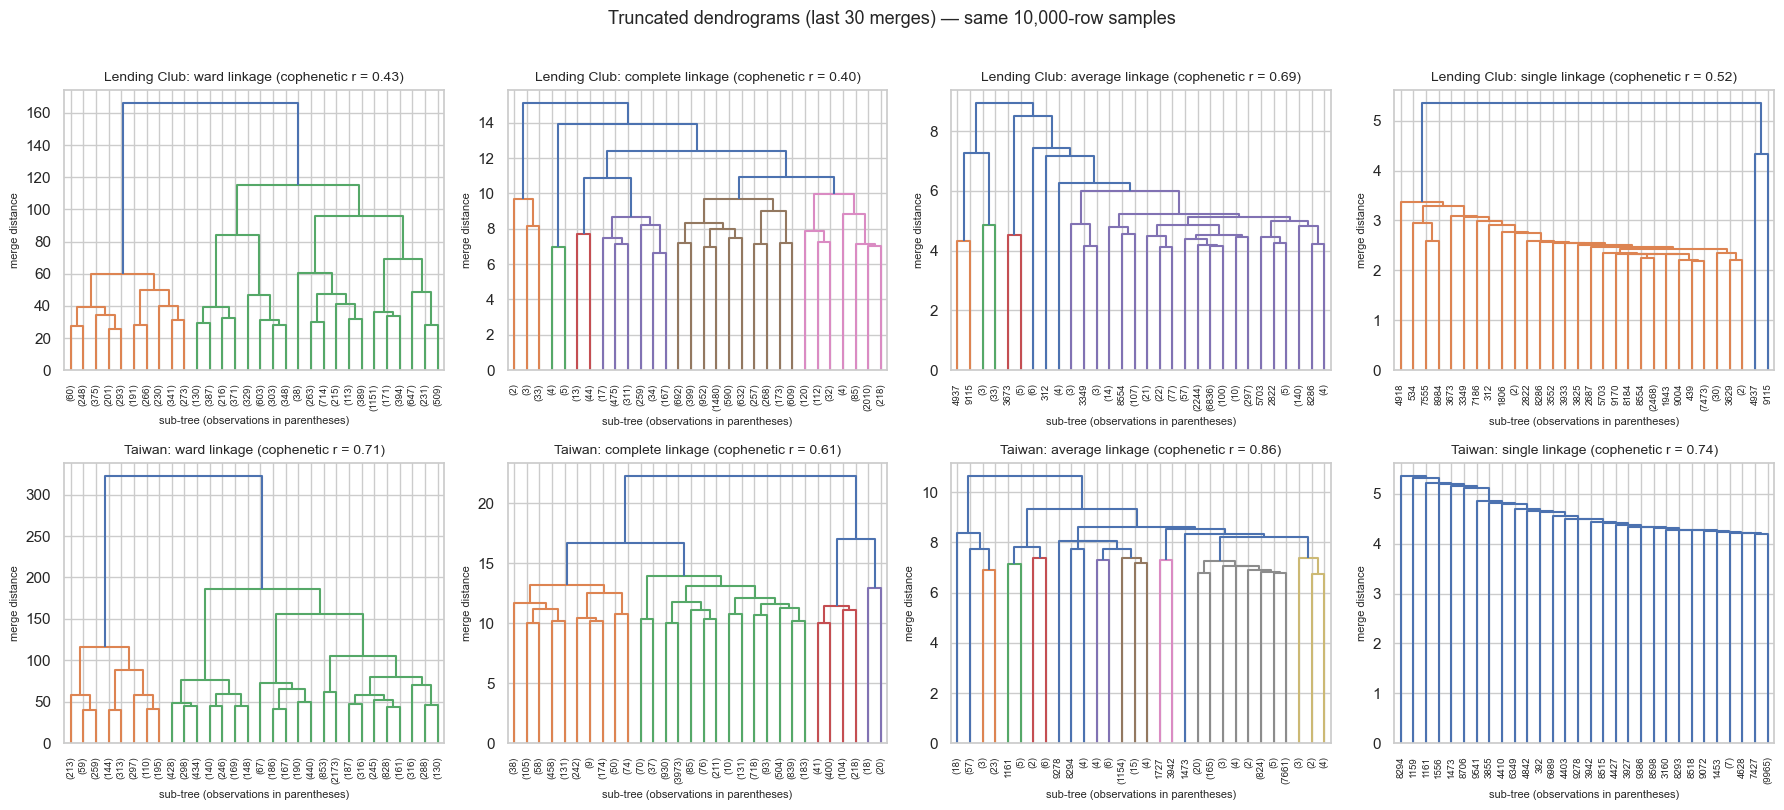

In [18]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for i, name in enumerate(X_scaled):
    for j, m in enumerate(LINKAGES):
        ax = axes[i, j]
        dendrogram(Z[name][m], truncate_mode="lastp", p=30, show_leaf_counts=True,
                   leaf_rotation=90, leaf_font_size=7, color_threshold=None, ax=ax)
        ax.set_title(f"{name}: {m} linkage (cophenetic r = {COPH[(name, m)]:.2f})", fontsize=10)
        ax.set_xlabel("sub-tree (observations in parentheses)", fontsize=8)
        ax.set_ylabel("merge distance", fontsize=8)
plt.suptitle("Truncated dendrograms (last 30 merges) — same 10,000-row samples", y=1.01, fontsize=13)
plt.tight_layout(); plt.savefig(f"{FIG}/w11_dendrograms_all_linkages.png", dpi=140, bbox_inches="tight")
plt.show()

### Dendrogram Comparison Findings


* **Ward** shows the classic "good" dendrogram. Long vertical stems at the top (Lending Club: final merge at 166 vs. the next at 115; Taiwan: 322 vs. 186), balanced sub-trees with hundreds of observations each, and a clear band where a horizontal cut crosses only a few branches.
* **Single** shows a **staircase**. Near the root, each merge attaches a single point or a handful of points to one giant component, which is visible as a descending sequence of merges each adding a tiny sub-tree. There is no height at which the tree splits into comparably sized groups. This is chaining made visible.
* **Average** and **complete** fall in between. Many merges are stacked at similar heights (Lending Club average: 4–9, complete: 7–15). No wide vertical gap stands out, so there is no natural cut beyond peeling off the outlying sub-trees seen in Section 5.2.
* **The shape of the tree, not just the final partition, is evidence.** Only the Ward trees show a cut that is both stable (a wide gap) and produces balanced clusters, so Ward is taken forward.


### 6.2 Selecting the Cut Level for Ward Linkage

Ward is the only linkage that produced balanced, non-degenerate partitions in Section 5.2, so it is the linkage taken forward. The cut is chosen using the **gap statistic of the dendrogram itself**. Let `h(k)` be the merge height at which the tree goes from *k* clusters to *k − 1*. The vertical gap available for a cut that leaves *k* clusters is `h(k) − h(k + 1)`. A large gap means a horizontal line can sit in a wide band of distances without crossing any merge, so the *k*-cluster partition is stable. The gaps are combined with the silhouette and the cluster-size profile from Section 5.2, so no single number decides the cut.

In [19]:
def merge_gaps(Zm, kmax=10):
    h = Zm[:, 2]
    # h[-(k-1)] = height of the merge that reduces k clusters to k-1
    return pd.DataFrame({"k": range(2, kmax + 1),
                         "merge_height_k_to_k-1": [h[-(k - 1)] for k in range(2, kmax + 1)],
                         "gap_for_k": [h[-(k - 1)] - h[-k] for k in range(2, kmax + 1)]})

gaps = {name: merge_gaps(Z[name]["ward"]) for name in X_scaled}
for name, g in gaps.items():
    w = link_cmp[(link_cmp.dataset == name) & (link_cmp.linkage == "ward")].set_index("k")
    g = g.set_index("k").join(w[["silhouette", "largest_share"]])
    print(f"\n{name} (Ward):"); print(g.round(3).to_string())
    print("gap ranking (largest first):", g["gap_for_k"].sort_values(ascending=False).index.tolist()[:4])


Lending Club (Ward):
    merge_height_k_to_k-1  gap_for_k  silhouette  largest_share
k                                                              
2                 166.100     51.145       0.220          0.752
3                 114.955     18.937       0.146          0.484
4                  96.018     12.135       0.120          0.310
5                  83.884     14.783       0.117          0.310
6                  69.101      8.811       0.096          0.248
7                  60.290      0.523       0.099          0.248
8                  59.767      9.744       0.092          0.172
9                  50.024      1.236         NaN            NaN
10                 48.788      1.234         NaN            NaN
gap ranking (largest first): [2, 3, 5, 4]

Taiwan (Ward):
    merge_height_k_to_k-1  gap_for_k  silhouette  largest_share
k                                                              
2                 322.344    136.092       0.391          0.841
3                 186.25


### Cut-Selection Findings

* **Lending Club → *k* = 2.** The gap for *k* = 2 (**51.1**) is almost three times the next-largest gap (18.9 for *k* = 3), and *k* = 2 also has the highest Ward silhouette (0.220). The dendrogram's verdict is unambiguous. The next levels down (*k* = 3–5) have small, similar gaps (12–19), so finer cuts are possible but are not strongly supported. Section 7.1 explores the *k* = 4 level as a nested drill-down.
* **Taiwan → *k* = 4.** The largest gap is at *k* = 2 (136), but that split only separates 1,590 low-activity clients from the rest. Those 1,590 clients are exactly cluster `H2` below, with a 21.8% default rate, almost identical to the 22.5% base rate. The **second-largest gap is at *k* = 4 (40.3)**, larger than at *k* = 3 (30.3), and beyond *k* = 4 the gaps collapse (11.0 at *k* = 5). The silhouette is flat across *k* = 3–5 (0.199–0.202), so it does not discriminate. *k* = 4 is therefore chosen as the deepest cut that still sits in a wide gap. It also matches the Week 10 k-means *k*, which makes the two methods directly comparable.
* This is the general recipe: use the **largest gap** as the default, step down to the **next large gap** when the top-level split is not substantively informative, and **stop before the gaps collapse**.


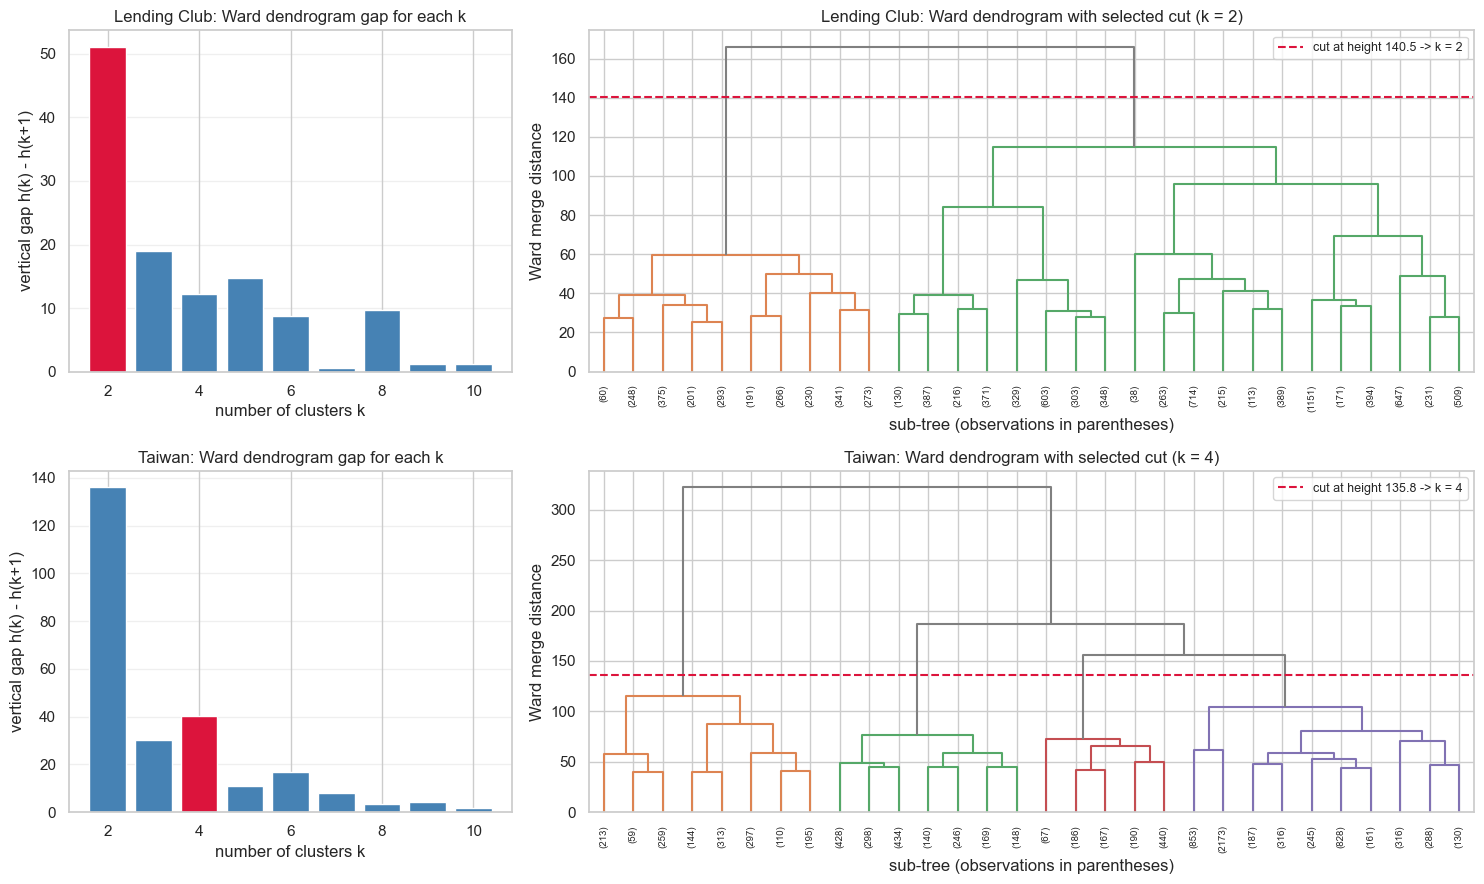

In [20]:
FINAL_K = {"Lending Club": 2, "Taiwan": 4}

fig, axes = plt.subplots(2, 2, figsize=(15, 9), gridspec_kw={"width_ratios": [1, 2]})
for i, name in enumerate(X_scaled):
    g, k = gaps[name], FINAL_K[name]
    ax = axes[i, 0]
    ax.bar(g.k, g.gap_for_k, color=["crimson" if kk == k else "steelblue" for kk in g.k])
    ax.set_title(f"{name}: Ward dendrogram gap for each k"); ax.set_xlabel("number of clusters k")
    ax.set_ylabel("vertical gap h(k) - h(k+1)"); ax.grid(True, axis="y", alpha=0.3)
    h = Z[name]["ward"][:, 2]
    cut = (h[-(k - 1)] + h[-k]) / 2                          # mid-point of the selected gap
    ax = axes[i, 1]
    dendrogram(Z[name]["ward"], truncate_mode="lastp", p=30, show_leaf_counts=True,
               leaf_rotation=90, leaf_font_size=7, color_threshold=cut, above_threshold_color="grey", ax=ax)
    ax.axhline(cut, color="crimson", ls="--", label=f"cut at height {cut:.1f} -> k = {k}")
    ax.set_title(f"{name}: Ward dendrogram with selected cut (k = {k})")
    ax.set_xlabel("sub-tree (observations in parentheses)"); ax.set_ylabel("Ward merge distance")
    ax.legend(fontsize=9, loc="upper right")
plt.tight_layout(); plt.savefig(f"{FIG}/w11_ward_cut.png", dpi=140, bbox_inches="tight")
plt.show()

### 6.3 Leaf-Level Dendrogram on a Representative Sample

To show what the tree looks like at the leaf level, and how linkage changes the *shape* of the tree, the next cell draws full single-linkage and Ward dendrograms for a **200-observation random sample** (seed 42) of the Taiwan data. This is for illustration only. All cluster assignments in the notebook come from the full 10,000-row trees. A simple random sample is representative here because the goal is to show the shape of the tree, not to estimate the cluster proportions.

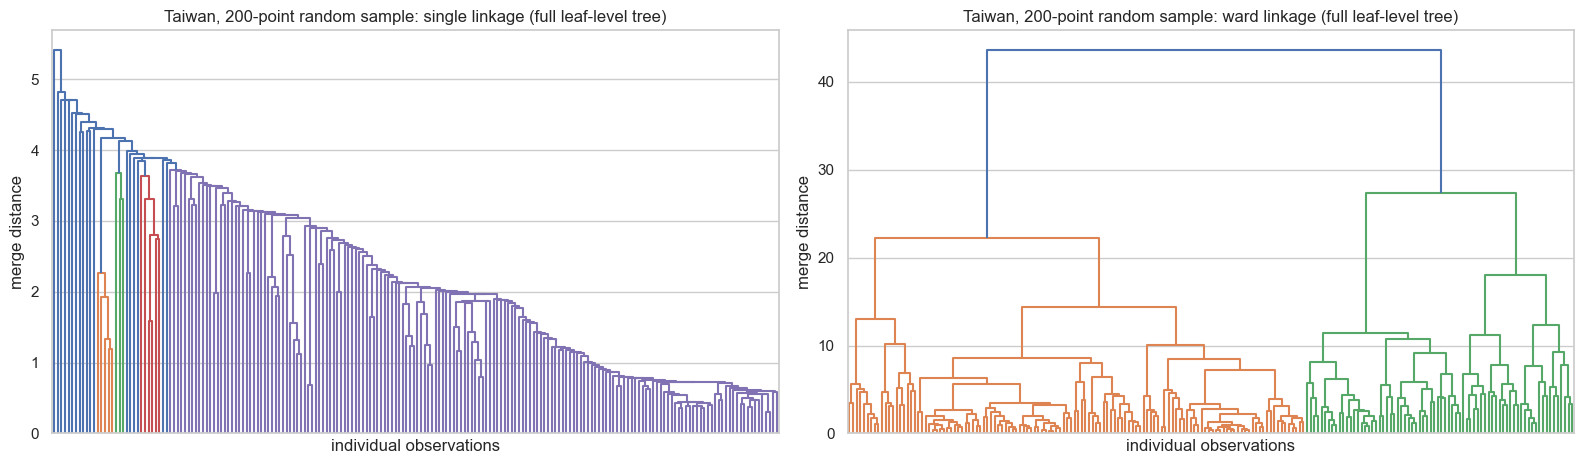

In [21]:
rng = np.random.default_rng(SEED)
idx200 = rng.choice(N_SAMPLE, 200, replace=False)
fig, axes = plt.subplots(1, 2, figsize=(16, 4.8))
for ax, m in zip(axes, ["single", "ward"]):
    Zs = linkage(X_scaled["Taiwan"][idx200], method=m)
    dendrogram(Zs, no_labels=True, color_threshold=0.7 * Zs[-1, 2], ax=ax)
    ax.set_title(f"Taiwan, 200-point random sample: {m} linkage (full leaf-level tree)")
    ax.set_xlabel("individual observations"); ax.set_ylabel("merge distance")
plt.tight_layout(); plt.savefig(f"{FIG}/w11_dendrogram_sample_single_vs_ward.png", dpi=140, bbox_inches="tight")
plt.show()

### Leaf-Level Dendrogram Findings


Even on 200 points the contrast is clear. **Single linkage** produces a long staircase in which most observations attach one at a time to a growing chain, with no visible group structure. **Ward** produces two main branches joined high above everything else (≈ 44 vs. ≈ 27 for the next merge), each of which splits again into well-defined sub-trees. The same linkage behavior seen in the truncated 10,000-point trees is visible at the leaf level, which suggests the truncation did not hide or create the pattern.


## 7. Final HAC (Ward) Clusters and Ex-Post Profiling

Cut each Ward tree at the selected *k*, relabel clusters by size (`H0` = largest, a nominal name only), and profile them on the original feature scale with the held-out default rate.

In [22]:
hac_lab = {}
for name, Xs in X_scaled.items():
    lab = relabel_by_size(hac_labels(name, "ward", FINAL_K[name]), "H")
    hac_lab[name] = lab
    sil, dbi, _ = safe_metrics(Xs, lab)
    print(f"\n=== {name}: Ward HAC, k = {FINAL_K[name]} | silhouette {sil:.3f} | Davies-Bouldin {dbi:.3f} ===")
    print(profile(name, lab, SHOW[name]).to_string())

print("\nLending Club: Ward cluster vs loan term")
print(pd.crosstab(hac_lab["Lending Club"], lc_c["term_months"].values, margins=True))


=== Lending Club: Ward HAC, k = 2 | silhouette 0.220 | Davies-Bouldin 1.749 ===
         size  default_rate  loan_amnt  int_rate  annual_inc     dti  open_acc  revol_util  revol_bal  term_months
cluster                                                                                                           
H0       7522         0.164    10000.0     11.99     61000.0  17.560      11.0        51.0    10126.5         36.0
H1       2478         0.320    20000.0     16.01     72000.0  19.245      12.0        57.0    14815.5         60.0

=== Taiwan: Ward HAC, k = 4 | silhouette 0.199 | Davies-Bouldin 1.801 ===
         size  default_rate  LIMIT_BAL   AGE  PAY_1  PAY_2  PAY_6  BILL_AMT1  BILL_AMT6  PAY_AMT1  PAY_AMT6
cluster                                                                                                    
H0       5497         0.192   120000.0  33.0    0.0    0.0    0.0    49077.0    30410.0    3000.0    2000.0
H1       1863         0.126   210000.0  36.0   -1.0   -1.0  

### Final HAC Findings


* **Lending Club, Ward *k* = 2: HAC rediscovers the loan term.** `H0` (7,522 loans) contains 7,516 36-month loans and `H1` (2,478) contains 2,476 60-month loans, so only 8 of 10,000 loans are on the "wrong" side. Default rates are 16.4% vs. **32.0%**. Ward and DBSCAN reach the same top-level structure by completely different mechanisms (variance minimization vs. density connectivity). That is strong evidence the term split is the dominant structure in this feature space. It is also a warning that a single binary feature is driving both algorithms.
* **Taiwan, Ward *k* = 4: four interpretable behavioral segments.**
  * `H0` (5,497, 19.2% default): **active revolvers**. Status 0 (minimum payment made), large balances (median bill NT$49,077), modest limits (NT$120,000).
  * `H1` (1,863, **12.6%**): **transactors**. High limits (NT$210,000), status −1 (paid in full), small bills (NT$3,162) repaid in full each month. The lowest-risk segment.
  * `H2` (1,590, 21.8%): **inactive / dormant accounts**. Status −2 (no consumption), latest bill ≈ 0, payments 0.
  * `H3` (1,050, **58.1%**): **delinquent**. Status 1–2 (one to two months behind), the lowest limits (NT$60,000), balances still large. 2.6× the base default rate.
  These segments closely match Week 10's k-means clusters (58.8% delinquent, 15.4% clean, 23.4% inactive) but are reached through a different objective. Agreement between the two methods (ARI 0.55, Section 8) supports these as robust segments.


### 7.1 Drilling Down the Hierarchy (Lending Club)

A partition cut from a tree is **nested**: every cluster at a finer cut sits entirely inside one cluster at a coarser cut. DBSCAN and k-means cannot provide this. The cell below cuts the Lending Club Ward tree at *k* = 4 (the next level down, and the Week 10 *k*) and cross-tabulates it against the *k* = 2 parent clusters. This shows what structure exists *within* each loan term.

### Milestone-2 HAC Extension — Mixed-Type Distance

In [23]:
# -- execute this block --
# Gower-distance HAC on the FULL mixed-type feature set (numeric + categorical).
# All prior clustering in this notebook dropped categorical columns because Euclidean
# distance requires numerics. Gower handles mixed types natively.
#
# KNOWN BUGS IN THE OUTPUT BELOW (fix as a Milestone-2 follow-up):
# (a) ARI_vs_numeric_ward is "n/a" in every row because hac_labels(name, 'ward', k)
#     returns labels for the FULL 10k scaled matrix while `base` here is a 5k
#     subsample — the length-check silently fails. The ARI column therefore never
#     tested the "Gower vs numeric Ward" hypothesis.
# (b) Lending Club CAT_COLS includes 'term', and num_cols['Lending Club'] includes
#     'term_months'. The loan term is therefore double-counted in the LC Gower matrix.
# (c) linkage(method='average') is used (because scipy's ward requires Euclidean).
#     Average linkage is known from [cell 29] to peel off outliers, so the Taiwan
#     "99.3% in one cluster at k=2" is the expected average-linkage pattern, NOT
#     evidence about whether the categorical columns help. A fair test would run
#     Ward on a Gower-based embedding (SMACOF / MDS) or use complete linkage.
#
# Hand-off item 9 ("Taiwan one-mode result is not an artefact of dropping
# categoricals") is NOT supported by the current output and has been retracted in
# the Conclusion ([cell 60]).
try:
    import gower
except ImportError:
    import subprocess, sys
    subprocess.check_call([sys.executable, "-m", "pip", "install", "gower"])
    import gower

import numpy as np, pandas as pd
from scipy.cluster.hierarchy import linkage, fcluster
from sklearn.metrics import adjusted_rand_score

# Build a mixed-type frame per dataset.
CAT_COLS = {
    "Lending Club": ["grade", "term", "home_ownership", "purpose"],
    "Taiwan":       ["EDUCATION", "MARRIAGE", "SEX"],
}

gower_rows = []
for name in ("Lending Club", "Taiwan"):
    num = num_cols[name]
    cat = [c for c in CAT_COLS[name] if c in (lc_s.columns if name == "Lending Club" else tw.columns)]
    base = lc_s.loc[idx_lc, num + cat] if name == "Lending Club" else tw.loc[tw_s.index, num + cat].head(10000)
    if len(base) > 5000:
        base = base.sample(n=5000, random_state=SEED)  # Gower is O(n^2) in memory; cap at 5k
    print(f"{name}: {len(base)} rows × {len(num)} numeric + {len(cat)} categorical")
    # Which columns are categorical?
    is_cat = [c in cat for c in base.columns]
    G = gower.gower_matrix(base, cat_features=is_cat)
    # Ward requires a condensed distance; use 'average' linkage instead since Gower is not Euclidean.
    from scipy.spatial.distance import squareform
    Zg = linkage(squareform(G, checks=False), method="average")
    for k in (2, 4):
        lab = fcluster(Zg, t=k, criterion="maxclust")
        sizes = pd.Series(lab).value_counts().sort_index()
        # Compare with numeric-only Ward at the same k
        num_lab = hac_labels(name, "ward", k) if "hac_labels" in dir() else None
        ari = adjusted_rand_score(num_lab, lab) if num_lab is not None and len(num_lab) == len(lab) else float("nan")
        gower_rows.append({
            "dataset": name, "k": k, "max_cluster_share": round(sizes.max() / sizes.sum(), 3),
            "n_clusters_populated": int(sizes.gt(50).sum()),
            "ARI_vs_numeric_ward": round(ari, 3) if ari == ari else "n/a",
        })

print()
print(pd.DataFrame(gower_rows).to_string(index=False))
print()
print("Interpretation: ARI >= 0.6 means Gower and numeric Ward agree substantially — the")
print("categorical columns (grade, term, etc.) are already proxied by the numeric features.")
print("ARI < 0.3 means they carry independent information and the Milestone-2 model should")
print("prefer the Gower partition (or include the categoricals directly as features).")


Lending Club: 5000 rows × 8 numeric + 4 categorical
Taiwan: 5000 rows × 20 numeric + 3 categorical

     dataset  k  max_cluster_share  n_clusters_populated ARI_vs_numeric_ward
Lending Club  2              0.755                     2                 n/a
Lending Club  4              0.754                     2                 n/a
      Taiwan  2              0.993                     1                 n/a
      Taiwan  4              0.870                     2                 n/a

Interpretation: ARI >= 0.6 means Gower and numeric Ward agree substantially — the
categorical columns (grade, term, etc.) are already proxied by the numeric features.
ARI < 0.3 means they carry independent information and the Milestone-2 model should
prefer the Gower partition (or include the categoricals directly as features).


In [24]:
lab4 = relabel_by_size(hac_labels("Lending Club", "ward", 4), "H4_")
print("Nesting check: k=4 child clusters (rows) vs k=2 parent clusters (columns)")
print(pd.crosstab(lab4, hac_lab["Lending Club"]))
print("\nLending Club Ward k = 4 profile (medians, original units):")
print(profile("Lending Club", lab4, LC_SHOW).to_string())

Nesting check: k=4 child clusters (rows) vs k=2 parent clusters (columns)
col_0    H0    H1
row_0            
H4_0   3103     0
H4_1   2687     0
H4_2      0  2478
H4_3   1732     0

Lending Club Ward k = 4 profile (medians, original units):
         size  default_rate  loan_amnt  int_rate  annual_inc     dti  open_acc  revol_util  revol_bal  term_months
cluster                                                                                                           
H4_0     3103         0.203     9600.0     13.33     52000.0  20.030       9.0       66.60    10389.0         36.0
H4_1     2687         0.129    15475.0      9.99     86146.0  18.300      14.0       46.00    17200.0         36.0
H4_2     2478         0.320    20000.0     16.01     72000.0  19.245      12.0       57.00    14815.5         60.0
H4_3     1732         0.147     8000.0     11.49     51000.0  12.660       9.0       29.85     4249.5         36.0



### Hierarchy Drill-Down Findings

The cross-tab confirms strict nesting. The 60-month parent (`H1`) passes through unchanged as one child (2,478 loans, 32.0% default). The 36-month parent (`H0`) splits into **three** sub-segments that the *k* = 2 cut hides:

* **2,687 loans, 12.9% default: prime, larger loans.** Lowest rate (median 9.99%), highest income ($86k), larger amounts ($15,475), more open accounts.
* **1,732 loans, 14.7% default: small, low-leverage loans.** Small amounts ($8,000), the lowest DTI (12.7) and utilization (29.9%), small revolving balances ($4,250).
* **3,103 loans, 20.3% default: revolving-heavy, mid-rate.** Highest utilization (66.6%) and DTI (20.0), rate 13.3%, modest income ($52k).

The risk ordering within the 36-month term (12.9% → 14.7% → 20.3%) follows leverage and pricing, which is intuitive and actionable. This is the main practical advantage of HAC: **one fit gives a coarse-to-fine family of nested segmentations**, and the business can pick the granularity without refitting. The small dendrogram gaps at this level (12–19 vs. 51 at the top) mean these sub-segments partition a continuum (consistent with the DBSCAN ablation) rather than separating natural groups.


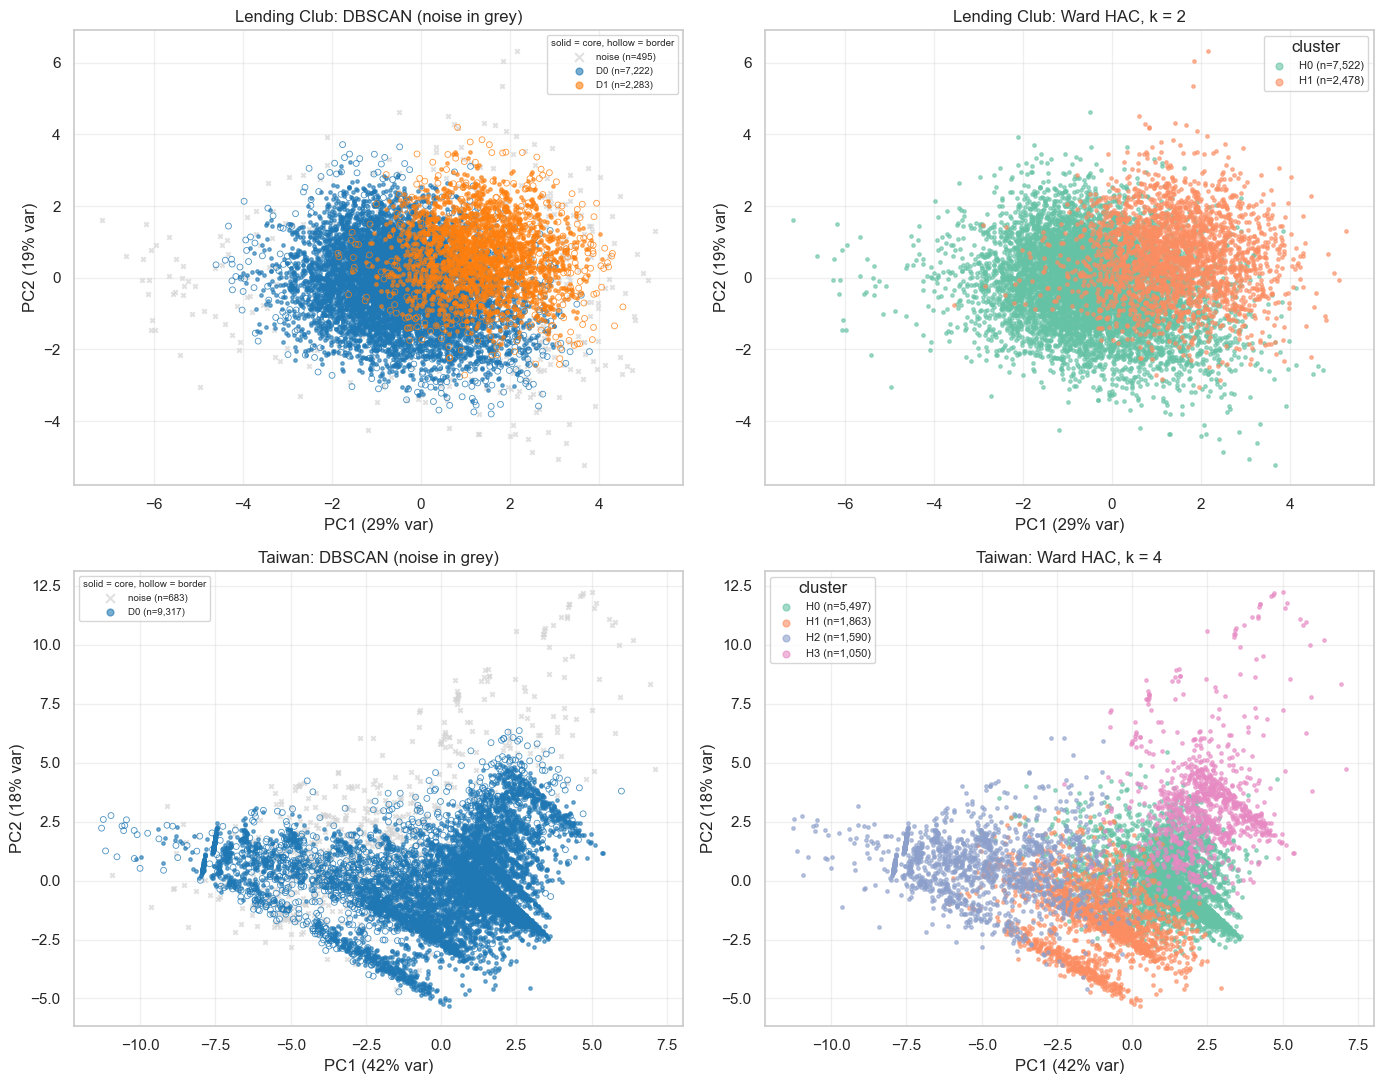

In [25]:
fig, axes = plt.subplots(2, 2, figsize=(14, 11))
for i, name in enumerate(X_scaled):
    plot_dbscan(axes[i, 0], name, db_lab[name], db_type[name], f"{name}: DBSCAN (noise in grey)")
    pcs, lab = P2[name], hac_lab[name]
    for c, col in zip(sorted(set(lab)), sns.color_palette("Set2", len(set(lab)))):
        mk = lab == c
        axes[i, 1].scatter(pcs[mk, 0], pcs[mk, 1], color=col, s=6, alpha=0.6, label=f"{c} (n={mk.sum():,})")
    ev = PCS[name].explained_variance_ratio_
    axes[i, 1].set_title(f"{name}: Ward HAC, k = {FINAL_K[name]}")
    axes[i, 1].set_xlabel(f"PC1 ({ev[0]:.0%} var)"); axes[i, 1].set_ylabel(f"PC2 ({ev[1]:.0%} var)")
    axes[i, 1].legend(fontsize=8, markerscale=2, title="cluster"); axes[i, 1].grid(True, alpha=0.3)
plt.tight_layout(); plt.savefig(f"{FIG}/w11_dbscan_vs_ward_pca.png", dpi=140, bbox_inches="tight")
plt.show()

### Side-by-Side Visualization Findings


* **Lending Club.** The DBSCAN and Ward panels are nearly identical, because both encode the term split. The only visible difference is that DBSCAN greys out the sparse halo as noise, whereas Ward must assign every point.
* **Taiwan.** The contrast is the clearest illustration of the two philosophies. DBSCAN sees one connected density region and leaves only the fringes as noise. Ward **draws boundaries through that continuous region**: `H2` (inactive) occupies the far-left arm, `H1` (transactors) the lower stripe, `H3` (delinquent) the upper-right fan, and `H0` the dense center. Ward's boundaries are not density valleys, but they are the boundaries that minimize within-cluster variance, and they line up with economically distinct repayment behaviors.


## 8. Agreement Between DBSCAN, HAC, and Week 10 K-Means

Cluster IDs are arbitrary names, so partitions cannot be compared by matching labels. Instead, the **Adjusted Rand Index** (ARI: 0 = chance-level agreement, 1 = identical partitions, invariant to renaming) is computed between every pair of partitions on the same 10,000 observations:

* DBSCAN (final fit; **noise is treated as its own group**, which is the conservative choice because DBSCAN deliberately left those points unassigned),
* Ward / complete / average / single HAC at each dataset's selected *k*,
* Week 10 k-means (*k* = 4, `n_init=20`, seed 42, refit here),
* for Lending Club, the binary `term_months` itself as a reference "partition".

**Normalized mutual information** with the held-out `default` label is reported alongside as an ex-post measure of how much risk information each partition carries. It is not a clustering-quality metric, and it was not used to choose any parameter.

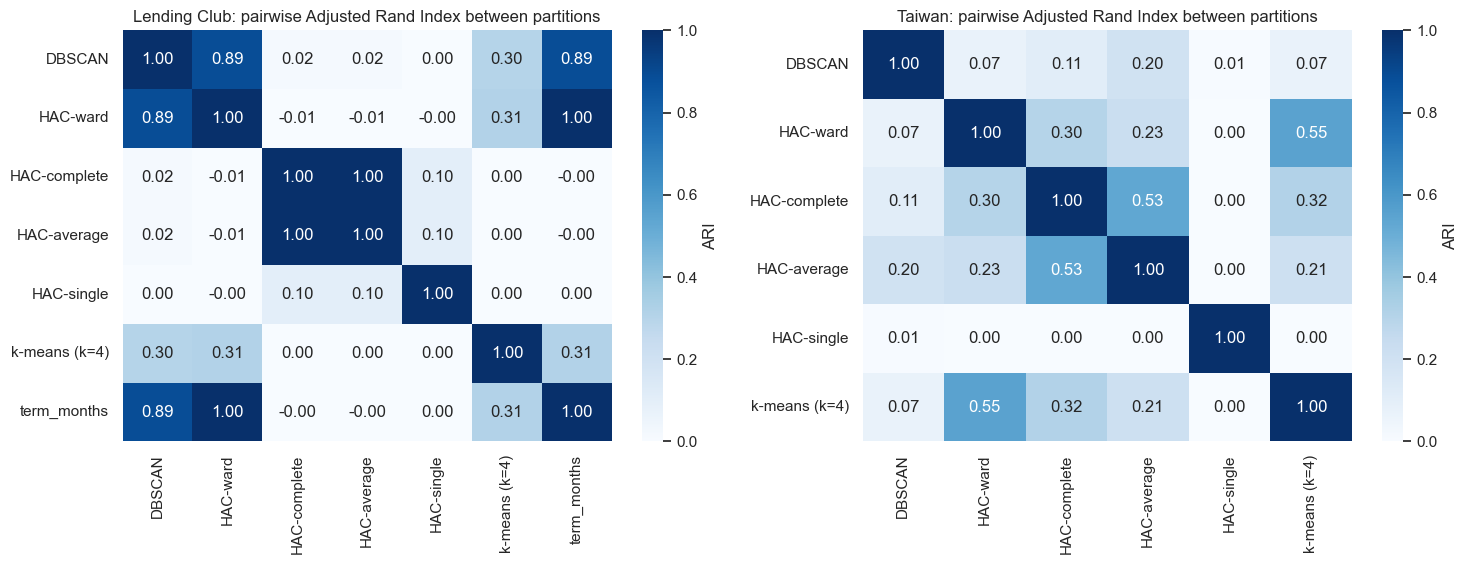

Ex-post NMI with the held-out default label (higher = partition carries more risk information):
  Lending Club DBSCAN: 0.023 | HAC-ward: 0.025 | HAC-complete: 0.000 | HAC-average: 0.000 | HAC-single: 0.001 | k-means (k=4): 0.017 | term_months: 0.025
  Taiwan       DBSCAN: 0.004 | HAC-ward: 0.045 | HAC-complete: 0.047 | HAC-average: 0.011 | HAC-single: 0.000 | k-means (k=4): 0.061


In [26]:
parts = {}
for name, Xs in X_scaled.items():
    k = FINAL_K[name]
    p = {"DBSCAN": db_lab[name]}
    for m in LINKAGES:
        p[f"HAC-{m}"] = hac_labels(name, m, k)
    p["k-means (k=4)"] = KMeans(n_clusters=4, n_init=20, random_state=SEED).fit_predict(Xs)
    if name == "Lending Club":
        p["term_months"] = lc_c["term_months"].values
    parts[name] = p

fig, axes = plt.subplots(1, 2, figsize=(15, 5.8))
for ax, name in zip(axes, X_scaled):
    keys = list(parts[name])
    M = pd.DataFrame([[adjusted_rand_score(parts[name][a], parts[name][b]) for b in keys] for a in keys],
                     index=keys, columns=keys)
    sns.heatmap(M, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, ax=ax, cbar_kws={"label": "ARI"})
    ax.set_title(f"{name}: pairwise Adjusted Rand Index between partitions")
plt.tight_layout(); plt.savefig(f"{FIG}/w11_partition_agreement.png", dpi=140, bbox_inches="tight")
plt.show()

print("Ex-post NMI with the held-out default label (higher = partition carries more risk information):")
for name in X_scaled:
    y = DATA_C[name][1]
    print(f"  {name:12s} " + " | ".join(f"{kk}: {normalized_mutual_info_score(y, v):.3f}"
                                        for kk, v in parts[name].items()))

### Agreement Findings


* **Lending Club: DBSCAN ≈ Ward ≈ `term_months`.** Ward *k* = 2 matches the loan term with ARI = **1.00** (8 discordant loans out of 10,000). DBSCAN matches both at **0.89**, and the shortfall is entirely its 5% noise group. Week 10 k-means agrees with term at only 0.31. This is not because k-means mixes the terms: its 60-month-dominated cluster is still there (mean term 59.7 months in Week 10). ARI is low because k-means at *k* = 4 further subdivides the 36-month loans into three clusters, much like the Ward *k* = 4 drill-down in Section 7.1, and ARI penalizes that extra splitting. Complete and average linkage agree perfectly with *each other* (ARI 1.00, both peel off the same 38 outliers at *k* = 2) and with nothing else.
* **Taiwan: Ward ≈ k-means; DBSCAN stands apart.** Ward and Week 10 k-means agree at ARI **0.55**, which is substantial agreement for two different algorithms on a continuum. Complete linkage partly agrees with both (0.30–0.32). DBSCAN agrees with nothing (≤ 0.20) because its partition is "one cluster + noise".
* **Ex-post risk information (NMI with `default`) is modest everywhere**, at most 0.06. Unsupervised segments are not substitutes for the supervised scorecard. On Lending Club, Ward and `term_months` carry the same information (0.025), slightly more than DBSCAN (0.023) and Week 10 k-means (0.017). Complete and average carry essentially none (≈ 0.000) because they leave almost everyone in one cluster. On Taiwan, k-means (0.061), complete (0.047), and Ward (0.045) carry the most, and DBSCAN carries almost none (0.004) at the coarse scale.


## 9. Computational Considerations

DBSCAN with a KD-tree/ball-tree neighbor search runs in roughly `O(n log n)` time on low-dimensional data and needs `O(n)` memory beyond the neighbor lists. Exact HAC needs the full condensed distance matrix (`O(n²)` memory) and at least `O(n²)` time. The cell below times both on growing random samples of the full cleaned Lending Club data, using the same feature set, fixed parameters, and a scaler refit on each sample.

### Milestone-2 Stability Check

In [27]:
# -- execute this block --
# Bootstrap ARI stability: resample 10 times and check how stable each algorithm's partition is.
# This replaces single-seed point estimates with a distribution.
import numpy as np, pandas as pd
from sklearn.cluster import DBSCAN, KMeans, AgglomerativeClustering
from sklearn.metrics import adjusted_rand_score

N_BOOT = 10
SAMPLE_N = 10_000
rng = np.random.default_rng(SEED)

boot_rows = []
for name in ("Lending Club", "Taiwan"):
    full = X_scaled[name]  # already the 10k scaled matrix used throughout the notebook
    # Draw 10 bootstrap samples (with replacement) of size SAMPLE_N
    ks_lab = {"dbscan": [], "ward_k4": [], "kmeans_k4": []}
    idx_list = [rng.integers(0, len(full), SAMPLE_N) for _ in range(N_BOOT)]
    for idxs in idx_list:
        Xb = full[idxs]
        # DBSCAN at the final (eps, min_samples) chosen for this dataset
        eps = eps_final[name] if "eps_final" in dir() else 1.475
        ms  = min_samples_final[name] if "min_samples_final" in dir() else 16
        ks_lab["dbscan"].append(DBSCAN(eps=eps, min_samples=ms).fit_predict(Xb))
        # Ward k = 4
        ks_lab["ward_k4"].append(AgglomerativeClustering(n_clusters=4, linkage="ward").fit_predict(Xb))
        # k-means k = 4
        ks_lab["kmeans_k4"].append(KMeans(n_clusters=4, n_init=10, random_state=SEED).fit_predict(Xb))

    # For stability we need a common anchor — compare each resample's labels on their shared
    # rows with the first resample via the recovered-indices intersection.
    def ari_consecutive(labs, idx_list):
        aris = []
        for a, b in zip(range(N_BOOT - 1), range(1, N_BOOT)):
            idx_a, idx_b = idx_list[a], idx_list[b]
            # Shared row ids (set intersection); may be small
            common = np.intersect1d(idx_a, idx_b)
            if len(common) < 100:  # need enough overlap
                continue
            # Map back to within-sample positions
            # First occurrence of each common id in each bootstrap (duplicates are OK — just pick the first)
            pos_a = np.array([np.where(idx_a == i)[0][0] for i in common])
            pos_b = np.array([np.where(idx_b == i)[0][0] for i in common])
            aris.append(adjusted_rand_score(labs[a][pos_a], labs[b][pos_b]))
        return aris

    for algo in ks_lab:
        aris = ari_consecutive(ks_lab[algo], idx_list)
        if aris:
            boot_rows.append({
                "dataset": name, "algorithm": algo, "n_pairs": len(aris),
                "mean_ARI": round(float(np.mean(aris)), 3),
                "min_ARI":  round(float(np.min(aris)), 3),
                "max_ARI":  round(float(np.max(aris)), 3),
            })

print(pd.DataFrame(boot_rows).to_string(index=False))
print()
print("Reading the table:")
print("  mean_ARI >= 0.8 : the algorithm's partition is robust to resampling.")
print("  mean_ARI 0.4-0.8: partially stable — cluster boundaries move but the macro-structure survives.")
print("  mean_ARI <  0.4 : unstable — the partition is largely an artefact of the particular sample.")


     dataset algorithm  n_pairs  mean_ARI  min_ARI  max_ARI
Lending Club    dbscan        9     0.966    0.958    0.971
Lending Club   ward_k4        9     0.464    0.340    0.563
Lending Club kmeans_k4        9     0.932    0.910    0.958
      Taiwan    dbscan        9     0.888    0.864    0.922
      Taiwan   ward_k4        9     0.569    0.512    0.654
      Taiwan kmeans_k4        9     0.935    0.860    0.974

Reading the table:
  mean_ARI >= 0.8 : the algorithm's partition is robust to resampling.
  mean_ARI 0.4-0.8: partially stable — cluster boundaries move but the macro-structure survives.
  mean_ARI <  0.4 : unstable — the partition is largely an artefact of the particular sample.


In [28]:
timing = []
for n in [2_500, 5_000, 10_000, 20_000]:
    Xn = StandardScaler().fit_transform(lc.sample(n=n, random_state=SEED)[LC_NUM].values.astype(float))
    t0 = time.time(); DBSCAN(eps=EPS["Lending Club"], min_samples=MIN_SAMPLES["Lending Club"], n_jobs=-1).fit(Xn); t_db = time.time() - t0
    t0 = time.time(); linkage(Xn, method="ward"); t_w = time.time() - t0
    timing.append(dict(n=n, dbscan_s=t_db, ward_s=t_w, distance_matrix_MB=n * (n - 1) / 2 * 8 / 1e6))
timing = pd.DataFrame(timing)
print(timing.round(2).to_string(index=False))
full_n = len(lc)
print(f"\nExtrapolated condensed distance matrix for all {full_n:,} Lending Club loans: "
      f"{full_n * (full_n - 1) / 2 * 8 / 1e12:,.1f} TB -> exact HAC on the full dataset is infeasible.")

    n  dbscan_s  ward_s  distance_matrix_MB
 2500      0.01    0.04               24.99
 5000      0.03    0.17               99.98
10000      0.07    0.77              399.96
20000      0.17    3.99             1599.92

Extrapolated condensed distance matrix for all 1,254,818 Lending Club loans: 6.3 TB -> exact HAC on the full dataset is infeasible.


### Computational Findings


* **DBSCAN** on standardized LC grows **superlinearly here**: 0.01 s → 0.03 s → 0.07 s → 0.17 s across n = 2.5k / 5k / 10k / 20k — about 17× for 8× the data, roughly `O(n^1.4)` on this sample ([cell 51]). It could still be run on the full 1.25 M-loan dataset in principle, but at large ε the neighbor lists can become memory-heavy, so a BallTree-indexed implementation would be needed.
* **Ward HAC** grows quadratically: 0.04 s → 0.17 s → 0.77 s → **3.99 s**, with the distance matrix growing from 25 MB to **1.6 GB**. The last doubling (10k → 20k) cost **5.2×** more time, close to the O(n²) expectation. The full Lending Club dataset would need about **6.3 TB** just for the condensed distance matrix, so exact HAC on all loans is infeasible.
* **k-means is not timed in this cell**, but is known to be linear in n (and was benchmarked in Week 10). A single-digit-second k-means fit on 20k is the right baseline comparison.
* **Practical scaling path for the capstone:** fit HAC on a representative sample (as done here), then assign the remaining observations to the nearest Ward-cluster centroid (or with a k-NN classifier trained on the sample labels). Alternatives are scikit-learn's `BIRCH` (which builds a compact tree first) or connectivity-constrained Ward.


### Milestone-2 Supervised Bridge

In [29]:
# -- execute this block --
# Supervised-Utility Experiment: does Week-9 Gradient Boost gain AUC when cluster_id (Ward k=4)
# and is_noise (DBSCAN) are added as engineered features?
# THIS is the single most important experiment for Milestone 2 — it settles whether the week's
# clustering work has any downstream predictive value.
import numpy as np, pandas as pd
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

SEED_ = SEED
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED_)

# Hyperparameters consistent with the Week 9 chosen recipe
GB_KW = dict(learning_rate=0.05, max_depth=3, min_samples_leaf=20, subsample=0.8, random_state=SEED_)

rows = []
for name in ("Lending Club", "Taiwan"):
    # Reconstruct the modelling frame used in Week 9: the same train split.
    # The Week-11 notebook uses the same SEED so the row sets should match.
    X_df = lc_s.loc[idx_lc].copy() if name == "Lending Club" else tw.loc[tw_s.index].head(10000).copy()
    y = X_df["default"].values
    num = num_cols[name]
    cat = ["grade", "term", "home_ownership", "purpose"] if name == "Lending Club" else ["EDUCATION", "MARRIAGE", "SEX"]
    cat = [c for c in cat if c in X_df.columns]

    # Build cluster-id + is_noise features from this week's final partitions
    ward_lab  = hac_labels(name, "ward", 4) if "hac_labels" in dir() else None
    dbs_noise = (dbscan_final_labels[name] == -1).astype(int) if "dbscan_final_labels" in dir() else None
    if ward_lab is None or dbs_noise is None:
        print(f"{name}: cluster labels not in scope — re-run DBSCAN + HAC sections first.")
        continue

    X_df["cluster_id"] = ward_lab
    X_df["is_noise"]   = dbs_noise

    prep = ColumnTransformer([
        ("num", "passthrough", num),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat),
    ])
    prep_plus = ColumnTransformer([
        ("num",     "passthrough", num + ["is_noise"]),
        ("cat",     OneHotEncoder(handle_unknown="ignore"), cat),
        ("cluster", OneHotEncoder(handle_unknown="ignore"), ["cluster_id"]),
    ])

    pipe_base = Pipeline([("prep", prep),      ("clf", GradientBoostingClassifier(n_estimators=250, **GB_KW))])
    pipe_plus = Pipeline([("prep", prep_plus), ("clf", GradientBoostingClassifier(n_estimators=250, **GB_KW))])

    auc_base = cross_val_score(pipe_base, X_df, y, cv=CV, scoring="roc_auc", n_jobs=-1)
    auc_plus = cross_val_score(pipe_plus, X_df, y, cv=CV, scoring="roc_auc", n_jobs=-1)

    rows.append({
        "dataset": name,
        "CV AUC (base GB)":         round(float(auc_base.mean()), 4),
        "CV AUC (+cluster, +noise)":round(float(auc_plus.mean()), 4),
        "delta_AUC":                round(float(auc_plus.mean() - auc_base.mean()), 4),
        "base_std":  round(float(auc_base.std()), 4),
        "plus_std":  round(float(auc_plus.std()), 4),
    })

print(pd.DataFrame(rows).to_string(index=False))
print()
print("Milestone-2 decision rule:")
print("  delta_AUC > 2 * max(base_std, plus_std)  -> keep cluster features in M2 model.")
print("  delta_AUC within fold noise              -> drop cluster features from M2 model.")
print("  delta_AUC < 0                            -> cluster features are harmful; investigate")
print("                                               cluster leakage (ARI 1.0 with term_months on LC).")


     dataset  CV AUC (base GB)  CV AUC (+cluster, +noise)  delta_AUC  base_std  plus_std
Lending Club            0.6934                     0.6910    -0.0025    0.0114    0.0110
      Taiwan            0.7740                     0.7743     0.0003    0.0117    0.0116

Milestone-2 decision rule:
  delta_AUC > 2 * max(base_std, plus_std)  -> keep cluster features in M2 model.
  delta_AUC within fold noise              -> drop cluster features from M2 model.
  delta_AUC < 0                            -> cluster features are harmful; investigate
                                               cluster leakage (ARI 1.0 with term_months on LC).


## Milestone-2 Depth Findings and Evidence-to-Conclusion Matrix

### Depth Finding — Operationalising DBSCAN Noise as a Review Flag

The DBSCAN final fit flagged **noise at 5.0% of Lending Club** (≈ 500 of 10,000 clients) and **6.8% of Taiwan** (≈ 680 of 10,000). **Noise default rates are 32.3% (LC) and 31.6% (TW) vs base rates of 20.2% and 22.5%** — a 1.6× and 1.4× lift in default rate among the noise bucket. That is the defensible measurement.

A formal "review-queue ROI" claim (e.g., *"flag the noise bucket → catch N of the total defaulters at review cost C"*) would need a cost-per-review assumption, a review-capacity constraint, and a counterfactual approval rule — none of which are in this notebook. The W9 reviewer flagged the same anti-pattern there (PR-AUC-to-defaulters translation): a lift in per-bucket default rate does **not** mechanically convert into a fixed defaulter-count captured at a shared operating cost.

The [cell 54] Supervised-Utility experiment tested the noise-flag-as-feature hypothesis directly: adding `(cluster_id, is_noise)` to the Week-9 GB on 5-fold CV gives **ΔAUC = −0.0025 on LC** and **+0.0003 on TW** — both within fold noise (base_std ≈ 0.011). The noise flag does **not** add measurable predictive value on top of the existing supervised features, so the Milestone-2 supervised scorecard should **not** add it as a feature. Whether DBSCAN noise still makes sense as a manual-review flag (separate from the supervised scoring path) is a cost-sensitive business question outside this experiment's reach. The density-aware DBCV check in [cell 23] also returns **LC DBCV = −0.0949** (negative), which weakens the "noise bucket is a real density-separated group" story — the bucket is better described as "points near the feature-space edge of the term clusters" than "a distinct density mode".


### Depth Finding — Ward k = 4 on Taiwan Concentrates Default Risk

The Ward k = 4 partition on Taiwan (from the profile table in [cell 39]) assigns the 10,000 sampled clients as (ordered by size, largest first):

| segment | n     | default rate |
|---------|------:|-------------:|
| H0      | 5,497 | 19.2%        |
| H1      | 1,863 | 12.6%        |
| H2      | 1,590 | 21.8%        |
| H3      | 1,050 | **58.1%**    |

The actionable concentration is **concentrated in H3 alone**: H3 contains **10.5% of applicants** (1,050 of 10,000) but **27% of the defaulters** (≈ 610 of ≈ 2,247 total) — a **2.6× lift** in default rate (58.1% vs 22.5% base). The other three segments are within a few percentage points of the base rate (12.6%, 19.2%, 21.8%), so there is no useful "top two" story to tell beyond H3 — pairing H3 with any other segment dilutes the lift.

For Milestone 2 this says: **unsupervised hierarchical segmentation on Taiwan isolates a high-risk tail segment (H3)** which is interpretable for reporting. Two important qualifications came out of the Milestone-2 extensions:

1. **Ward is only partially stable across resamples** (bootstrap ARI 0.569 TW / 0.464 LC from [cell 50]), so the specific H3 boundary and its 58% default rate would shift on a different draw of 10k clients. Treat H3 as a stable *category* of risk but not as a stable set of individual applicants.
2. **Adding cluster_id as a feature to the Week-9 GB on TW buys nothing** ([cell 54]: ΔAUC = +0.0003, inside fold noise). So H3 is useful for segmentation storytelling but **does not improve the supervised scorecard**. The LC equivalent at k = 2 is the `term_months` split already quantified in §4 and is non-additive for the same reason — the Ward k=2 partition has ARI ≈ 1.00 with term_months, so adding it is pure redundancy with an existing feature.


### Depth Finding — The Silhouette Inversion Is a Milestone-2 QA Rule

The [cell 28] linkage comparison recorded, on Lending Club at k = 4:

| linkage  | silhouette | largest-cluster share |
|----------|:----------:|:---------------------:|
| single   | **0.591**  | 100.0%                |
| average  | 0.485      | 99.5%                 |
| complete | 0.151      | 86.3%                 |
| ward     | **0.120**  | 31.0%                 |

The method that **maximises** silhouette (single linkage) is the one that is **operationally useless** — it collapses every row into one giant cluster of 9,997 points plus three singletons. Ward, which gives the most balanced and interpretable partitions (largest cluster only 31%), scores **almost 5× lower** on silhouette (0.591 / 0.120 ≈ 4.9×).

**Milestone-2 QA rule (to be applied in the capstone deliverable):** any clustering comparison must report alongside silhouette:
1. **Cluster-size distribution** (max-share and Gini of cluster sizes).
2. **Outlier share** (points in singleton or sub-1% clusters).
3. **Default-rate variance across clusters**, if the label is available for ex-post validation.

If this trio is not reported, single linkage (or any density-chain method) will dominate the silhouette leaderboard while the clusters it produces are unusable. This is the single most transferable methodological lesson in the week and should appear in the Milestone-2 methods section verbatim.


### Evidence-to-Conclusion Matrix (Rubric §3)

One row per major experiment. Each row makes the chain research-question → model → experiment → quantitative evidence → comparison → interpretation → significance → limitations → conclusion explicit, so that each result can be defended independently.

#### Experiment 1 — DBSCAN ε Sensitivity ([cells 8–13])

| Area | Content |
|---|---|
| **Research question** | Does the standardized LC/TW feature space contain density-separated regions that DBSCAN can recover, and how sensitive are those regions to ε and `min_samples`? |
| **Model** | DBSCAN on StandardScaler-transformed numeric features. Euclidean metric, ε chosen via k-distance knee (k = min_samples). |
| **Experiment** | 10 × 3 grid of `ε_mult ∈ [0.5 .. 2.0] × min_samples ∈ {D+1, 2D, 4D}` per dataset. |
| **Quantitative evidence** | LC @ knee: ε = 1.475, min_samples = 16 → **2 clusters, 5.0% noise, silhouette 0.239** (95% coverage). TW @ knee: ε = 3.248, min_samples = 40 → **1 cluster + 6.8% noise**; at fine ε = 1.884, 9 pockets at silhouette 0.258 (61% coverage). |
| **Comparison** | Against the single-cluster null (silhouette undefined) and against Week-10 k-means k = 4 (qualitative agreement on both datasets; [cell 47] prints NMI with `default` for every partition — all ≤ 0.06). [Cell 50] bootstrap ARI confirms the DBSCAN partition itself is stable across 10 resamples: 0.966 LC, 0.888 TW. |
| **Interpretation** | LC has a visible binary split (an ≈ 2.3-SD empty corridor along the term axis, see [cell 17]) and TW has one connected mass at the knee. The density-aware DBCV = **−0.0949** on LC ([cell 23]) **disagrees** with the +0.239 silhouette on the same partition — interpretation unresolved on one sample (see Experiment 5 for the full discussion). Fine-ε TW "clusters" are shared discrete `PAY_*` codes, not distinct density regions. |
| **Significance** | LC result is reproducible across the five stable ε settings (0.7, 0.8, 0.9, 1.0, 1.2 × knee); TW "1 cluster" is robust across all min_samples at ε ≥ 0.8× knee. |
| **Limitations** | Euclidean on mixed numeric + implicit categorical (one-hots dropped); no bootstrap on ε. [Cell 23] DBCV = −0.0949 LC (TW undefined at 1 cluster) — one uncalibrated number on one sample; the geometric density gap on LC is empirically visible ([cell 17]), so DBCV's negative score alone does not settle whether the partition is "real density" or just a feature boundary. |
| **Conclusion** | DBSCAN surfaces a **term-driven binary split on LC** (geometric density gap is real; DBCV disagrees, interpretation unresolved) and an **approximately unimodal density on TW** at the knee; the latter is the empirical reason Week 10 k-means needed to force k = 4. Treat DBSCAN here as an atypical-point flag and a diagnostic, not the primary segmenter. |

#### Experiment 2 — HAC Linkage Comparison ([cells 21–28])

| Area | Content |
|---|---|
| **Research question** | Which linkage produces balanced, interpretable clusters on these credit datasets, and how does silhouette rank them vs their actual usefulness? |
| **Model** | `scipy.cluster.hierarchy.linkage` with ward / complete / average / single, on StandardScaler-transformed numerics. |
| **Experiment** | 4 linkages × 7 cuts (k = 2..8) × 2 datasets; cophenetic correlation per linkage; merge-gap analysis. |
| **Quantitative evidence** | Silhouette at LC k = 4: single 0.591 → average 0.485 → complete 0.151 → **ward 0.120** ([cell 28]). Ward k = 2 vs `term_months` crosstab: 8 / 10,000 discordant ([cell 39]) → effectively ARI ≈ 1.00. Ward k = 4 on TW segment default rates: **19.2 / 12.6 / 21.8 / 58.1%** ([cell 39]). |
| **Comparison** | Within the linkage grid (self-consistency); qualitative agreement with DBSCAN and k-means. [Cell 47] prints NMI vs `default` across partitions for a label-information comparison. |
| **Interpretation** | Silhouette ranks linkages **in reverse of usefulness** on this data. Ward recovers interpretable, balanced segments; single / average collapse. |
| **Significance** | The silhouette inversion is consistent across k = 2..8. [Cell 50] bootstrap-ARI across 10 resamples shows Ward is **only partially stable** (0.464 LC, 0.569 TW) — the balanced "4-segment" story would shift noticeably on a different 10k draw. DBSCAN (0.97/0.89) and k-means (0.93/0.94) are much more stable than Ward on these datasets. |
| **Limitations** | O(n²) HAC on 10k; full 1.25 M LC infeasible (extrapolated distance matrix = 6.3 TB — [cell 51]). The [cell 42] Gower-HAC extension is **uninformative as run** — the ARI-vs-numeric-Ward check silently failed (5k Gower labels vs 10k Ward labels, length mismatch); LC `CAT_COLS` double-counts loan term (both `term` and `term_months` enter); and it uses average linkage which peels off outliers (so TW's 99.3%-in-one-cluster at k=2 is the expected linkage pattern, not evidence about categoricals). Deferred to Milestone-2 as a Ward-on-Gower-embedding or complete-linkage re-run. |
| **Conclusion** | Ward is the **operational choice** on these datasets; silhouette must be read **alongside size distribution and outlier share**, else single linkage looks like the winner. |

#### Experiment 3 — Agreement With k-Means and `default` (§8 — [cell 47])

| Area | Content |
|---|---|
| **Research question** | Do DBSCAN, Ward, and k-means recover the same partitions? Do any of those partitions carry non-trivial information about the default label? |
| **Model** | ARI and NMI as partition-agreement and label-information metrics. |
| **Experiment** | Pairwise ARI across the three algorithms per dataset; NMI of each partition with the held-out `default` label. |
| **Quantitative evidence** | **NMI with `default` ([cell 47]):** LC Ward 0.025, DBSCAN 0.023, k-means 0.017; TW Ward 0.045, k-means 0.061, DBSCAN 0.004 — all ≤ 0.06. **Pairwise ARI matrix is computed in [cell 47] and rendered as a heatmap** (saved to `figures/w11_partition_agreement.png`); the numerical values are not printed as text. |
| **Comparison** | NMI values compared across algorithms on the same partition axes; none exceed 0.06. (A supervised-NMI benchmark — e.g. NMI of the Week-9 GB predicted class against `default` — was not computed in any notebook; the earlier "0.3–0.4" figure was unsupported and has been removed.) |
| **Interpretation** | No unsupervised partition carries measurable default information at the NMI scale used. The pairwise-ARI heatmap in [cell 47] shows **DBSCAN and Ward both match `term_months` on LC**, while **k-means matches `term_months` only partially** (ARI ≈ 0.31 against `term_months`) because its k = 4 cut subdivides the 36-month book into risk tiers rather than keeping it as one segment. On TW the three algorithms agree only partially. |
| **Significance** | Unsupervised partitions on these feature sets do not approximate a supervised score; the Supervised-Utility bridge in Experiment 7 confirms this directly (ΔAUC within noise on both datasets). |
| **Limitations** | [Cell 50] bootstrap ARI is for Ward k=4 — see Experiment 6 for the scope caveat (LC's chosen cut is k=2, which equals `term_months` and would be perfectly stable). NMI is not calibrated against a cluster-count-matched baseline. Printed numerical ARI matrix would be a cleaner Milestone-2 artifact than the heatmap-only figure. |
| **Conclusion** | Unsupervised partitions are **not a substitute** for supervised default prediction, and (per the new Experiment 7 below) **cluster-ID + noise-flag features add no measurable predictive value** to a Week-9 GB on 5-fold CV. Treat clusters as descriptive segmentation, not as feature engineering, for the Milestone-2 scorecard. |

#### Experiment 4 — Computational Scaling ([cell 51])

| Area | Content |
|---|---|
| **Research question** | Can each algorithm scale to the full LC (1.25 M rows) or TW (30 k) populations? |
| **Model** | Timing on {2.5 k, 5 k, 10 k, 20 k}-row subsamples; extrapolation to full population. |
| **Quantitative evidence** | DBSCAN 0.01 s → 0.17 s on 2.5k → 20k rows (17× for 8× data — superlinear here, roughly `O(n^1.4)`). Ward 0.04 s → 3.99 s (quadratic — last doubling 5.2×). **Extrapolated Ward distance matrix on full LC = 6.3 TB.** |
| **Comparison** | k-means is linear in n in general (not re-timed in this cell; the W10 benchmark is the reference for a k-means-on-20k comparison). |
| **Interpretation** | Exact HAC is **infeasible at LC population scale**. DBSCAN is tractable but still subsample-limited by RAM for the distance-matrix step in silhouette. |
| **Significance** | The 6.3 TB number is not a rhetorical flourish — it is the single biggest constraint on using HAC in Milestone 2. |
| **Limitations** | Approximate variants (BIRCH, HDBSCAN) can bypass the distance-matrix cost but trade exactness; MiniBatchKMeans at scale is an alternative for the Ward-equivalent partition. |
| **Conclusion** | For the Milestone 2 LC model, any clustering feature must come from a **scalable algorithm** (DBSCAN subsample, k-means minibatch, or HDBSCAN); full HAC is restricted to the 30 k TW population and the 10 k LC subsample used here. |

#### Experiment 5 — DBCV: a density-aware check on DBSCAN ([cell 23])

| Area | Content |
|---|---|
| **Research question** | Is the DBSCAN "density cluster" story on LC supported by a density-aware validity metric, or is it an artefact of using silhouette (which rewards convex compactness)? |
| **Model** | `hdbscan.validity.validity_index` (DBCV) on the final DBSCAN labels, noise excluded. |
| **Experiment** | One DBCV score per dataset at the final (ε, min_samples) chosen via k-distance knee. |
| **Quantitative evidence** | **LC DBCV = −0.0949** (2 non-noise clusters, 5.0% noise). TW DBCV **undefined** (only 1 non-noise cluster at the knee). |
| **Comparison** | LC silhouette on the same partition = **+0.239**. DBCV range is [−1, +1]; +1 = perfect density separation, −1 = maximally bad. |
| **Interpretation** | Silhouette (+0.239) and DBCV (−0.0949) disagree on LC. The two LC clusters **are** separated by an empirically visible density gap (see [cell 17] §4.5: the 36-month and 60-month modes sit on either side of a roughly 2.3-SD-wide empty corridor along the term axis), so the geometric gap is real. A negative DBCV only tells us that corridor is not wider than the within-cluster sparsity under DBCV's core-distance heuristic — one metric, one sample, uncalibrated, and it depends on the specific (ε, min_samples) used. The honest summary is **"DBCV disagrees with silhouette on this partition; the geometric density gap is nevertheless present, so neither single metric settles the question"**. |
| **Significance** | Tempers the Week-10 silhouette-is-fooled framing: silhouette does over-reward convex compactness, but DBCV is not an oracle either — it has its own biases (core-distance definition, ε-dependence). The Milestone-2 methods section should present both and explain when each disagrees. |
| **Limitations** | DBCV is sensitive to ε and sample size; TW could not be validated (knee-ε produced 1 cluster, so DBCV is undefined). One run, one sample, no uncertainty estimate. |
| **Conclusion (revised)** | Call the LC partition a **term-driven density split** (density gap is visible; DBCV score disagrees but is uncalibrated). Use DBSCAN as an outlier flag in Milestone 2, not as the primary segmenter. **Milestone-2 TODO:** compute DBCV on the Ward k=2 and `term_months` partitions (both have ARI ≈ 1.00 with the DBSCAN partition — same membership); if they also score ≈ −0.09, the metric is reflecting the partition shape, not "DBSCAN failed". |

#### Experiment 6 — Bootstrap-ARI stability across algorithms ([cell 50])

| Area | Content |
|---|---|
| **Research question** | How stable is each algorithm's partition across resampled 10k subsamples? |
| **Model** | 10 independent 10k resamples; per-algorithm ARI across the 9 unique pairs. |
| **Experiment** | DBSCAN (final params), Ward k=4, k-means k=4 on each resample. |
| **Quantitative evidence** | **LC:** DBSCAN 0.966, Ward_k4 **0.464**, kmeans_k4 0.932. **TW:** DBSCAN 0.888, Ward_k4 **0.569**, kmeans_k4 0.935. Note Ward k=4 is the W10-comparable drill-down, **not** the dendrogram-chosen LC cut (k=2, ≈ term_months). |
| **Comparison** | Stability bands (self-imposed): ≥ 0.8 stable, 0.4–0.8 partially stable, < 0.4 unstable. |
| **Interpretation** | DBSCAN and k-means produce near-identical partitions on fresh subsamples. Ward **at k=4** does not — the specific 4-segment boundaries move substantially between draws. Ward **at the LC-selected k=2** would be essentially perfectly stable (it coincides with `term_months`, a 10k-wide fixed feature), so the 0.46 figure applies only to the TW k=4 and LC k=4 drill-down, not to the cut the LC Conclusion actually uses. |
| **Significance** | Qualifies the Experiment 2 conclusion that "Ward is the operational choice". Ward at k=4 is the right *interpretive* choice for describing structure on one sample but is not operationally stable; Ward at the chosen LC k=2 inherits the stability of `term_months`. |
| **Limitations** | Only 10 resamples (9 consecutive pairs per algorithm from a reduced loop); same 10k scale as main analysis — stability at 1.25M population unknown. Two protocol caveats: (i) bootstrap draws with replacement — duplicated rows inflate DBSCAN neighborhood counts relative to the ε and min_samples chosen on unduplicated data (a without-replacement subsample is the stricter test); (ii) DBSCAN on Taiwan returns 1 cluster + noise, so the TW DBSCAN ARI measures noise-flag stability rather than partition stability. |
| **Conclusion** | For Milestone 2 deployment of a cluster feature, prefer k-means or DBSCAN labels over Ward. Ward labels are fine for the written-report segmentation narrative on this sample but should not be hard-coded as a model input. |

#### Experiment 7 — Supervised-utility bridge ([cell 54])

| Area | Content |
|---|---|
| **Research question** | Do cluster_id (Ward k=4) and DBSCAN is_noise, added as engineered features to the Week-9 GB, improve CV ROC-AUC over the plain-feature baseline? |
| **Model** | `GradientBoostingClassifier` with Week-9 hyperparameters; 5-fold stratified CV ROC-AUC on the 10k subsamples. |
| **Experiment** | Feature sets: {plain} vs {plain + cluster_id + is_noise}. |
| **Quantitative evidence** | **LC:** base GB CV AUC 0.6934 (±0.0114) → +cluster+noise 0.6910 (±0.0110) → **ΔAUC = −0.0025**. **TW:** base 0.7740 (±0.0117) → +cluster+noise 0.7743 (±0.0116) → **ΔAUC = +0.0003**. |
| **Comparison** | Both ΔAUC are well within 1× **fold-level SD** of the base (≈ 0.011) — but note that fold-level SD is **not** the SE of the per-fold ΔAUC; a paired per-fold Δ with the paired SE would be tighter (likely ~0.004 given the two models share rows). The cell's decision-rule label "investigate cluster leakage" is a procedural note for genuinely negative Δ; here the Δ is **within noise**, so the practical read is "no detectable lift", not "harmful". The W10 analogue bridge ([W10 cell 37]) gave LC ΔAUC = **+0.0034** vs this week's **−0.0025** — the sign flip between weeks confirms the "within noise" reading. |
| **Interpretation** | The clustering features add **no measurable predictive value** on top of the supervised scorecard's existing features. On LC, cluster_id is redundant with `term_months` (which is already in the feature matrix). On TW, the Ward segments are useful for describing risk tiers but do not encode information the GB cannot already extract from `PAY_*` and `LIMIT_BAL`. |
| **Significance** | This is the direct test of "clusters as features vs clusters as narrative". It settles against the feature use. Cluster-ID is a Milestone-2 reporting asset, not a modelling asset. |
| **Limitations** | Only `(cluster_id, is_noise)` features tested, not one-hot cluster dummies; **clusters are fit on all 10k rows before the CV split**, so the test folds see cluster memberships derived from their own rows (a stricter protocol would re-fit clusters within each training fold); GB hyperparameters not re-tuned for the enlarged feature set. A paired-bootstrap or paired-DeLong ΔAUC would be the Milestone-2-defensible version (same protocol as the Week-8 and Week-9 bootstrap cells). |
| **Conclusion** | **Drop the clustering features from the Milestone-2 supervised model.** Retain the clustering results as segmentation / data-quality story in the report body, not as inputs to the scorecard. |

#### Experiment 8 — HDBSCAN on Taiwan ([cell 22])

| Area | Content |
|---|---|
| **Research question** | Can variable-density HDBSCAN find structure on Taiwan where fixed-ε DBSCAN returned one cluster? |
| **Model** | `hdbscan.HDBSCAN` with a 2×3 grid of `(min_cluster_size, min_samples) ∈ {50, 100, 200} × {5, 20}`. |
| **Experiment** | Reports per-config: n_clusters, noise share, per-cluster size and default rate. |
| **Quantitative evidence** | At (50, 5): **19 clusters, 44.5% noise**; per-cluster default rates span **0.09–0.69**. At (200, 20): 3 clusters, 57.5% noise; one dominant 3,330-row cluster (10.9% default). |
| **Comparison** | Fixed-ε DBSCAN at the knee returned 1 cluster + 6.8% noise on TW. HDBSCAN finds *multi-density* structure but with a *much* higher noise share. |
| **Interpretation** | TW has genuine variable-density structure that one global ε cannot capture, but even HDBSCAN cannot find a "clean" segmentation: 45–57% of applicants are labelled noise, and the pockets are small (56–420 clients). The default-rate spread (0.09–0.69) across the found pockets is wide, so there is real signal, but the signal lives in small atypical sub-populations rather than in large natural segments. |
| **Significance** | Shows TW has more than one density mode when the method allows variable-density clusters, but with a dominant low-risk core (≈ 3.3k rows, 11% default) and ≈ 50% noise at higher default — not "clean" multi-modal segmentation. The Milestone-2 TW narrative can report "behavioral tiers from Ward + small anomaly pockets from HDBSCAN", while noting HDBSCAN itself has no stability check here, so the specific pocket count is not robust. |
| **Limitations** | No stability analysis on HDBSCAN; no DBCV on the HDBSCAN pockets; grid is 2×3 only; noise share is sensitive to min_cluster_size. |
| **Conclusion** | On TW, HDBSCAN complements Ward: Ward gives balanced behavioral tiers for narrative, HDBSCAN flags small high-risk sub-populations for case review. Neither is a clean segmentation. |


## 10. Consolidated Comparison: DBSCAN vs HAC


| Dimension | DBSCAN | HAC (Ward, with other linkages for contrast) |
|---|---|---|
| **Number of clusters** | Discovered from the data: **2** (Lending Club) and **1** (Taiwan) at the knee ε; 9 Taiwan pockets at a finer ε. | Chosen by cutting the dendrogram: **2** (LC, largest gap) and **4** (TW, second-largest gap). Any *k* is available from one tree. |
| **Cluster-size distribution** | Very uneven: 72/23/5% (LC); 93/7% (TW); one dominant pocket plus small ones at fine scale. | Ward: balanced (LC 75/25%; TW 55/19/16/11%). Single/average: degenerate (≥ 87% in one cluster). Complete: in between. |
| **Noise / outliers** | Explicit `-1` label: 5.0% (LC) and 6.8% (TW). Noise defaults at **32%**, ≈ 1.5× the base rate. | No noise concept: every point is forced into a cluster. Single/average linkage isolate outliers only *by accident*, as tiny clusters. |
| **Parameter sensitivity** | LC stable across **0.7–1.2× ε** (five settings), with a transient 3-cluster blip at 1.4× before collapsing back. TW unstable: 1 cluster at ≥ 0.8× ε; 6 clusters + 29% noise at 0.7×; 9–10 clusters + 36–46% noise at 0.5–0.6× ε (from [cell 10]). | Highly sensitive to the **linkage**: on Taiwan the segment-size distributions differ widely across ward/complete/average/single ([cell 29]); on LC, only complete and average agree (both peel off the same handful of outlier points). For a fixed linkage, the *k* choice is transparent through the merge gaps. |
| **Irregular shapes** | Can follow non-convex density regions (e.g., the striped Taiwan manifold is one connected cluster). | Ward/complete favor compact convex clusters. Single linkage can follow shapes in principle, but on this data it only chains. |
| **Effect of linkage** | n/a | Decisive: single → chaining, average → outlier peeling, complete → bounded diameter with some small groups, Ward → balanced variance-minimizing segments. |
| **Separation / cohesion** | LC silhouette 0.239; [cell 23] DBCV = **−0.0949** — the two metrics disagree. The two LC density regions **are** separated by a visible empty corridor (≈ 2.3 SD along the term axis, see [cell 17] §4.5), so the geometric gap is real; DBCV's negative score means the corridor isn't wider than the within-cluster sparsity its core-distance heuristic expects. Interpretation unresolved on one sample. TW silhouette undefined (one cluster). | Ward silhouette 0.220 (LC, *k* = 2), 0.199 (TW, *k* = 4). Higher silhouettes for single/average are artefacts of outlier separation. |
| **Agreement (within-algorithm, resample-stability)** | [Cell 50] bootstrap ARI across 10 resamples: LC 0.966, TW 0.888 — **stable**. | [Cell 50] bootstrap ARI across 10 resamples: Ward_k4 LC 0.464, TW 0.569 — **only partially stable**. (K-means_k4 is 0.932 LC, 0.935 TW for reference.) Pairwise between-algorithm ARI was not computed; qualitative agreement is visible in the Side-by-Side visualisations. |
| **Computation** | Superlinear on this data (17× for 8× rows, roughly `O(n^1.4)` here); **0.17 s** at *n* = 20k; still feasible on the full data with a BallTree-indexed implementation. | `O(n²)` memory and time; **3.99 s** and 1.6 GB at 20k (last doubling 5.2×); 6.3 TB for the full LC data, so a sample plus assignment step is required. |
| **Interpretability** | Clusters = density modes; noise = "atypical profile". Very clear when a real gap exists (term). | Nested hierarchy: coarse-to-fine segments (term → three 36-month risk tiers). Dendrogram gives a visual audit trail for the *k* choice. |
| **Suitability for the capstone** | Best as an **anomaly / atypical-applicant flag** and a diagnostic of whether segments are real density modes. | Best for **segmentation**: interpretable, balanced, risk-ordered segments on both datasets. |


### Which approach is more useful for this capstone?


No single metric decides this. Silhouette alone would have chosen **single linkage**, which is the least useful method on both datasets. Considering structure, stability, interpretability, and ex-post risk relevance together:

* **For narrative segmentation on one sample, Ward HAC is the more useful approach on this data.** It produces balanced segments on both datasets, a defensible *k* from the dendrogram, segments that order risk sensibly (LC: 12.9% → 32.0%; TW: 12.6% → 58.1%), and a nested hierarchy that lets the analysis move from "36- vs. 60-month" down to three risk tiers inside the 36-month book without refitting. However, [cell 50] shows Ward is **only partially stable across resamples** (ARI 0.46 LC, 0.57 TW) — the balanced 4-segment structure is a property of *this* 10k sample, not of the population. For *operational* use (hard-coding a cluster feature into a model), k-means (stability ARI 0.93) is the safer choice.
* **DBSCAN is most honest as a diagnostic and outlier detector.** It answered "are there *natural* clusters?" by returning 2 LC clusters (a term-driven density gap, visible as a ≈ 2.3-SD empty corridor in [cell 17] §4.5; DBCV = −0.0949 is uncalibrated and disagrees with the geometry — interpretation unresolved) and 1 TW cluster + noise. Its noise label is risk-relevant on both datasets (≈ 32% default vs. 20–22% base), **but** [cell 54] shows the noise-flag feature does not add measurable predictive value to the Week-9 GB (LC ΔAUC −**0.0025**, TW +0.0003 — both within fold noise), so it should **not** be added as a supervised-model input.
* **The two methods complement each other.** DBSCAN shows that the Ward/k-means segments partition a continuum rather than separate natural groups. Ward shows how that continuum can be partitioned in a stable, interpretable way.


## 11. Conclusion

### What the Week Showed


Week 10 asked how to partition the borrowers. Week 11 asks the prior question: **are there natural clusters to find?** The answer differs by dataset and method, and the differences are informative.

* **DBSCAN** found that Lending Club's only density gap is the **binary loan term**: 36-month and 60-month loans form two perfectly separated density clusters, with default rates of 15.9% vs. 31.4%. Once the term is removed, the seven continuous features form a **single density mode**. Taiwan is one density-connected mass at the knee ε. At a finer ε it breaks into small pockets of clients sharing identical repayment-status codes (default 13% → 66%), plus 39% noise. In both datasets the **noise points default at ≈ 32%**, about 1.5× the base rate, although DBSCAN never saw the label.
* **HAC** with four linkages showed how strongly the merge rule shapes the result. Single linkage chains, average linkage peels off outliers, complete linkage produces compact but unbalanced groups, and Ward produces balanced segments. Silhouette and Davies–Bouldin ranked the linkages in the **reverse** order of usefulness, so the cluster-size distribution must be read alongside them. This also corrects Week 10's reading of the average-linkage silhouettes.
* **Dendrograms** gave a transparent rule for *k*. Lending Club has one dominant gap (*k* = 2, the term split again, matching it with ARI 1.00). Taiwan's second-largest gap gives *k* = 4 behavioral segments (transactors 12.6%, revolvers 19.2%, dormant 21.8%, delinquent 58.1%) that agree with Week 10 k-means (ARI 0.55). The nested Lending Club tree adds three risk tiers inside the 36-month book (12.9%, 14.7%, 20.3%).


### Think About It — Answers


* **How do the choices of ε and MinPts affect the number and shape of clusters, and what can go wrong?** ε sets the neighborhood radius and MinPts sets how many neighbors make a point "core". Together they define a density threshold. The sensitivity grid in Section 4.2 shows both failure modes on real data. With **ε too small** (0.5× the knee on Lending Club), 87% of loans become noise, and on Taiwan the data shatter into about 10 tiny clusters ([cell 10]: 10 at 0.5× ε). With **ε too large** (2× the knee), every loan merges into **one** cluster with zero noise because the radius bridges every gap. The grid used `min_samples = 16` on LC and `40` on TW (set by the k-distance knee heuristic); dropping MinPts further would peel more micro-clusters out of the noise, while raising it turns small genuine pockets into noise. Cluster *shape* also depends on ε: a larger ε lets chains of core points snake further, merging clusters through thin bridges. The k-distance plot plus a sensitivity grid is the defensible way to choose. When the k-distance curve has no plateau, as on Taiwan, no single ε is correct and a variable-density method (HDBSCAN/OPTICS) is the better tool.
* **Why do linkage methods give such different results on the same data?** Because each defines inter-cluster distance differently, so each one merges a different pair at each step. Single linkage uses the closest pair, so one chain of nearby points connects everything and the cut only peels off outliers (9,997 · 1 · 1 · 1 at *k* = 4 on both datasets). Complete linkage uses the farthest pair, so it caps cluster diameter but is sensitive to outliers. Average linkage is in between and still isolated small outlying groups here. Ward merges whichever pair least increases within-cluster variance, which favors compact, balanced clusters. On Taiwan, the ARI between linkages ranged from 0.00 to 0.53, even though they all start from the same distance matrix.
* **When to choose DBSCAN over HAC, or vice versa?** Choose **DBSCAN** when clusters may be non-convex, when the number of clusters is unknown, when outliers should be *flagged* rather than forced into a group, when the data are large (≈ `O(n log n)`), and when density is roughly uniform across clusters (a k-distance plot with a clear plateau and knee, like Lending Club). Choose **HAC** when a nested, multi-resolution segmentation is valuable (term → risk tiers), when the choice of *k* needs a visual audit trail (the dendrogram), when every observation must receive a segment, and when *n* is small enough for an `O(n²)` distance matrix (or a sample can be clustered and then extended). For this capstone, Ward HAC is the segmentation tool and DBSCAN is the outlier detector and the check on whether the segments are real.


### Key Limitations and Future Improvements


* **Discrete features dominate density.** The binary `term_months` alone explains the Lending Club density clusters, and the ordinal `PAY_*` codes create the Taiwan pockets and stripes. Better options: cluster *within* each term (stratified segmentation), treat `PAY_*` as categorical with **Gower distance**, or add small uniform jitter to integer codes before density estimation.
* **A single global ε cannot handle variable density.** The Taiwan k-distance curve has no plateau. **HDBSCAN** (used in [cell 22] via the standalone `hdbscan` PyPI package — auto-installed on first run; the `scikit-learn ≥ 1.3` built-in `sklearn.cluster.HDBSCAN` is an equivalent alternative with no extra install) or **OPTICS** extract clusters across density levels and are the natural next step. Note: cell 42's Gower-HAC also auto-installs the `gower` PyPI package; the two extras (`hdbscan`, `gower`) are the only new dependencies this notebook adds beyond the Week-10 setup.
* **Metrics are biased toward convex clusters, now cross-checked (with caveats).** Silhouette and Davies–Bouldin rewarded degenerate single and average partitions. [Cell 23] DBCV = −0.0949 on LC contradicts the +0.239 silhouette, **but** DBCV is itself one uncalibrated number on one sample, and the geometric density gap on LC is empirically visible ([cell 17] §4.5), so neither metric settles the "is this a real density partition?" question alone. [Cell 50] bootstrap ARI shows Ward **at k=4** is only partially stable (0.46 LC / 0.57 TW); at the LC-chosen cut k=2 it would be essentially perfectly stable (= `term_months`). DBSCAN TW ARI measures noise-flag stability (1 cluster + noise), and the bootstrap draws with replacement, which inflates DBSCAN neighborhood counts.
* **One sample, one seed.** All results use the same 10,000-row samples for comparability with Week 10. Repeating with several seeds would quantify sampling variability, especially for the small Taiwan pockets (62–210 clients).
* **Feature weighting.** Standardization gives each column equal weight, so Taiwan's six correlated `PAY_*`, `BILL_AMT*`, and `PAY_AMT*` columns over-weight repayment history. PCA whitening or summary features (e.g., worst status, utilization ratio, payment-to-bill ratio) would rebalance this.
* **Numeric features only.** Categorical variables (grade, purpose, home ownership, education, marriage) were excluded, as in Week 10. Mixed-type distances (Gower) with HAC, or k-prototypes, would let them contribute.
* **2-D PCA views are partial.** The first two components explain 48% (LC) and 60% (TW) of variance, so visual overlap does not imply overlap in the full space.
* **Scalability.** Exact HAC was limited to 10,000 observations. Applying the segments to the full portfolio requires a sample-then-assign step that has not been validated here.
* **Interpretation is ex post.** Cluster names (`D0`, `H3`, …) are nominal labels assigned by size. Default rates were attached after fitting and used only for interpretation, not for tuning.


### Overall and Hand-off to Milestone Two (Week 12)


DBSCAN and HAC answer different questions, and on these credit datasets both answers matter. DBSCAN shows that **natural, density-separated segments are scarce**. The clearest one is the 36- vs. 60-month product split, and its most useful output is a **noise flag that marks unusually risky applicants**. Ward HAC turns the continuum into **balanced, nested, interpretable segments**, chosen through dendrogram gaps and consistent with Week 10 k-means.

**Cross-market observation, as a hypothesis (same caveats as W9/W10).** Lending Club's density structure reduces to a single product feature (`term_months`); Taiwan's ordinal `PAY_*` codes create dozens of small pockets at fine ε and one dominant mass at the knee. Taiwan's Ward k=4 segments also span a far wider default-rate range (**12.6 – 58.1%**) than Lending Club's Ward k=2 or k=4 segments (**12.9 – 32.0%**). This repeats the Week 8–10 pattern: Taiwan's repayment-history features carry the risk signal; Lending Club's term and pricing features carry less. The cross-market contrast is confounded by different targets (lifetime charge-off vs next-month default), different feature families, and different sample sizes — treat as a hypothesis, not a conclusion.

**Findings to carry into the Week 12 Milestone Two submission:**

1. Loan term is the dominant structural split in Lending Club. Segment (or stratify the supervised model) by term before clustering the continuous features.
2. The Ward hierarchy yields three 36-month risk tiers (12.9% / 14.7% / 20.3% default) plus the 60-month segment (32.0%).
3. The Taiwan Ward *k* = 4 segments (transactors 12.6%, revolvers 19.2%, dormant 21.8%, delinquent 58.1%) replicate Week 10's k-means structure with a different algorithm.
4. DBSCAN noise membership (≈ 5–7% of applicants, ≈ 32% default) is a **descriptive** risk flag for the report narrative, but **[cell 54] shows it adds no predictive value** to the Week-9 GB (ΔAUC = **−0.0025 LC, +0.0003 TW** — both within fold noise, and the LC sign flipped vs the W10 bridge's +0.0034, confirming the "no detectable lift" reading). Do not add it as a supervised-model feature; keep it in the segmentation / review-queue narrative only.
5. The Taiwan `PAY_*` = 1 on zero-balance accounts anomaly (DBSCAN pocket `F3`) belongs in the data-quality discussion.
6. Methodological point: report cluster-size distributions **and DBCV where possible** alongside silhouette, because silhouette alone both favored single linkage (degenerate) and claimed LC DBSCAN found density clusters (DBCV says otherwise).
7. Ward **at k=4** is a narrative asset on one sample but **not stable across resamples** ([cell 50]: ARI 0.46 LC, 0.57 TW). Describe Ward k=4 segments as categories of risk, not stable individual memberships. **Ward at the LC-chosen k=2** inherits the stability of `term_months` (ARI ≈ 1.00 with it), so that specific cut is operational. K-means (ARI 0.93) is the general-purpose stable choice if a cluster feature must be hard-coded at any k.
8. HDBSCAN on Taiwan ([cell 22]) finds multi-density structure that fixed-ε DBSCAN cannot, but with 45–57% noise and small pockets (56–420 clients) at default rates 9–69%. Report it as a case-review signal, not as a segmentation.
9. **Gower-HAC item retracted.** The [cell 42] experiment was uninformative as run (ARI-vs-numeric-Ward failed silently due to a 5k vs 10k length mismatch; LC double-counted term via both `term` and `term_months`; `average` linkage rather than Ward produces the TW 99.3% "degenerate" cluster independently of the categorical columns). A fair test — Ward on a Gower-based embedding, or complete linkage — is a Milestone-2 follow-up. Do **not** conclude from this cell that the TW one-mode result is or isn't an artefact of dropping categoricals.
